In [ ]:
!pip install -q huggingface_hub

In [ ]:
from huggingface_hub import snapshot_download

dataset_path = snapshot_download(
    repo_id="Adit-jain/Soccana_player_ball_detection_v1",
    repo_type="dataset",
    local_dir="/content/Soccana"
)

print("Dataset downloaded successfully!")
print("Location:", dataset_path)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Dataset downloaded successfully!
Location: /content/Soccana


In [ ]:
import os

for root, dirs, files in os.walk("/content/Soccana"):
    level = root.replace("/content/Soccana", "").count(os.sep)

    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")
        for file in files[:5]:
            print("  " * (level + 1) + file)

Soccana/
  V1.zip
  README.md
  .gitattributes
  .cache/
    huggingface/
      .gitignore
      CACHEDIR.TAG
      download/
        V1.zip.lock
        README.md.lock
        V1.zip.metadata
        README.md.metadata
        .gitattributes.lock
      trees/
        9e768912f134a7d68b58ddc9db9bcd3f6fbe39b7.json
  samples/
    Figure_10.png
    Figure_8.png
    Figure_5.png
    Figure_7.png
    Figure_1.png


In [ ]:
import zipfile
import os

zip_path = "/content/Soccana/V1.zip"
extract_path = "/content/Soccana/"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction complete!")

Extraction complete!


In [ ]:
import os

for root, dirs, files in os.walk("/content/Soccana/V1"):
    level = root.replace("/content/Soccana/V1", "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")
        for file in files[:5]:
            print("  " * (level + 1) + file)

V1/
  data.yaml
  samples/
    Figure_10.png
    Figure_8.png
    Figure_5.png
    Figure_7.png
    Figure_1.png
  images/
    train/
      v3_sahi_320_4611.jpg
      v5_temp_6075.jpg
      v7_sahi_160_6939.jpg
      v3_sahi_320_5040.jpg
      tbd_v2_139.jpg
    test/
      v3_sahi_320_1379.jpg
      v3_sahi_320_1517.jpg
      v7_sahi_160_2212.jpg
      v2_temp_sahi_320_669.jpg
      v7_1953.jpg
  coco_train_annotations/
    _annotations.coco.json
  coco_test_annotations/
    _annotations.coco.json
  labels/
    train.cache
    test.cache
    classes.txt
    train/
      v3_sahi_320_4244.txt
      v7_sahi_160_6730.txt
      v3_sahi_640_5179.txt
      v7_6197.txt
      v12_933.txt
    test/
      v3_sahi_640_1637.txt
      v2_temp_sahi_320_710.txt
      v3_sahi_640_1634.txt
      v12_sahi_320_345.txt
      v3_sahi_640_1624.txt


In [ ]:
# Check data.yaml
with open("/content/Soccana/V1/data.yaml", "r") as f:
    print("===== DATA.YAML =====")
    print(f.read())

# Check classes.txt
with open("/content/Soccana/V1/labels/classes.txt", "r") as f:
    print("\n===== CLASSES.TXT =====")
    print(f.read())

===== DATA.YAML =====
names:
  0: Player
  1: Ball
  2: Referee
path: F:\Datasets\SoccerAnalysis_Final\V1
train: images/train
val: images/test


===== CLASSES.TXT =====
Player
Ball
Referee



In [ ]:
yaml_path = "/content/Soccana/V1/data.yaml"

with open(yaml_path, "r") as f:
    yaml_content = f.read()

yaml_content = yaml_content.replace(
    r"F:\Datasets\SoccerAnalysis_Final\V1",
    "/content/Soccana/V1"
)

with open(yaml_path, "w") as f:
    f.write(yaml_content)

print("Updated data.yaml:")
print(yaml_content)

Updated data.yaml:
names:
  0: Player
  1: Ball
  2: Referee
path: /content/Soccana/V1
train: images/train
val: images/test



In [ ]:
import os

base_path = "/content/Soccana/V1"

folders = [
    "images/train",
    "images/test",
    "labels/train",
    "labels/test"
]

for folder in folders:
    folder_path = os.path.join(base_path, folder)
    files = os.listdir(folder_path)

    if folder.startswith("images"):
        count = sum(f.lower().endswith((".jpg", ".jpeg", ".png")) for f in files)
    else:
        count = sum(f.endswith(".txt") for f in files)

    print(f"{folder}: {count} files")

images/train: 8677 files
images/test: 2996 files
labels/train: 8677 files
labels/test: 2996 files


In [ ]:
for split in ["train", "test"]:
    image_dir = f"{base_path}/images/{split}"
    label_dir = f"{base_path}/labels/{split}"

    images = {
        os.path.splitext(f)[0]
        for f in os.listdir(image_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    }

    labels = {
        os.path.splitext(f)[0]
        for f in os.listdir(label_dir)
        if f.endswith(".txt")
    }

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Images without labels:", len(images - labels))
    print("Labels without images:", len(labels - images))


TRAIN
Images: 8677
Labels: 8677
Images without labels: 0
Labels without images: 0

TEST
Images: 2996
Labels: 2996
Images without labels: 0
Labels without images: 0


In [ ]:
import os

base_path = "/content/Soccana/V1"

valid_classes = {0, 1, 2}
invalid_lines = []
empty_files = 0
total_boxes = 0

for split in ["train", "test"]:
    label_dir = f"{base_path}/labels/{split}"

    for filename in os.listdir(label_dir):
        if not filename.endswith(".txt"):
            continue

        file_path = os.path.join(label_dir, filename)

        with open(file_path, "r") as f:
            lines = f.readlines()

        if len(lines) == 0:
            empty_files += 1

        for line_number, line in enumerate(lines, start=1):
            parts = line.strip().split()

            if len(parts) != 5:
                invalid_lines.append((filename, line_number, "Wrong format"))
                continue

            try:
                class_id = int(parts[0])
                x, y, w, h = map(float, parts[1:])
            except ValueError:
                invalid_lines.append((filename, line_number, "Non-numeric value"))
                continue

            if class_id not in valid_classes:
                invalid_lines.append((filename, line_number, "Invalid class ID"))
                continue

            if not all(0 <= v <= 1 for v in [x, y, w, h]):
                invalid_lines.append((filename, line_number, "Coordinate out of range"))
                continue

            if w <= 0 or h <= 0:
                invalid_lines.append((filename, line_number, "Invalid box size"))
                continue

            total_boxes += 1

print("Total valid bounding boxes:", total_boxes)
print("Empty label files:", empty_files)
print("Invalid annotations:", len(invalid_lines))

print("\nFirst 10 errors:")
print(invalid_lines[:10])

Total valid bounding boxes: 64729
Empty label files: 3501
Invalid annotations: 0

First 10 errors:
[]


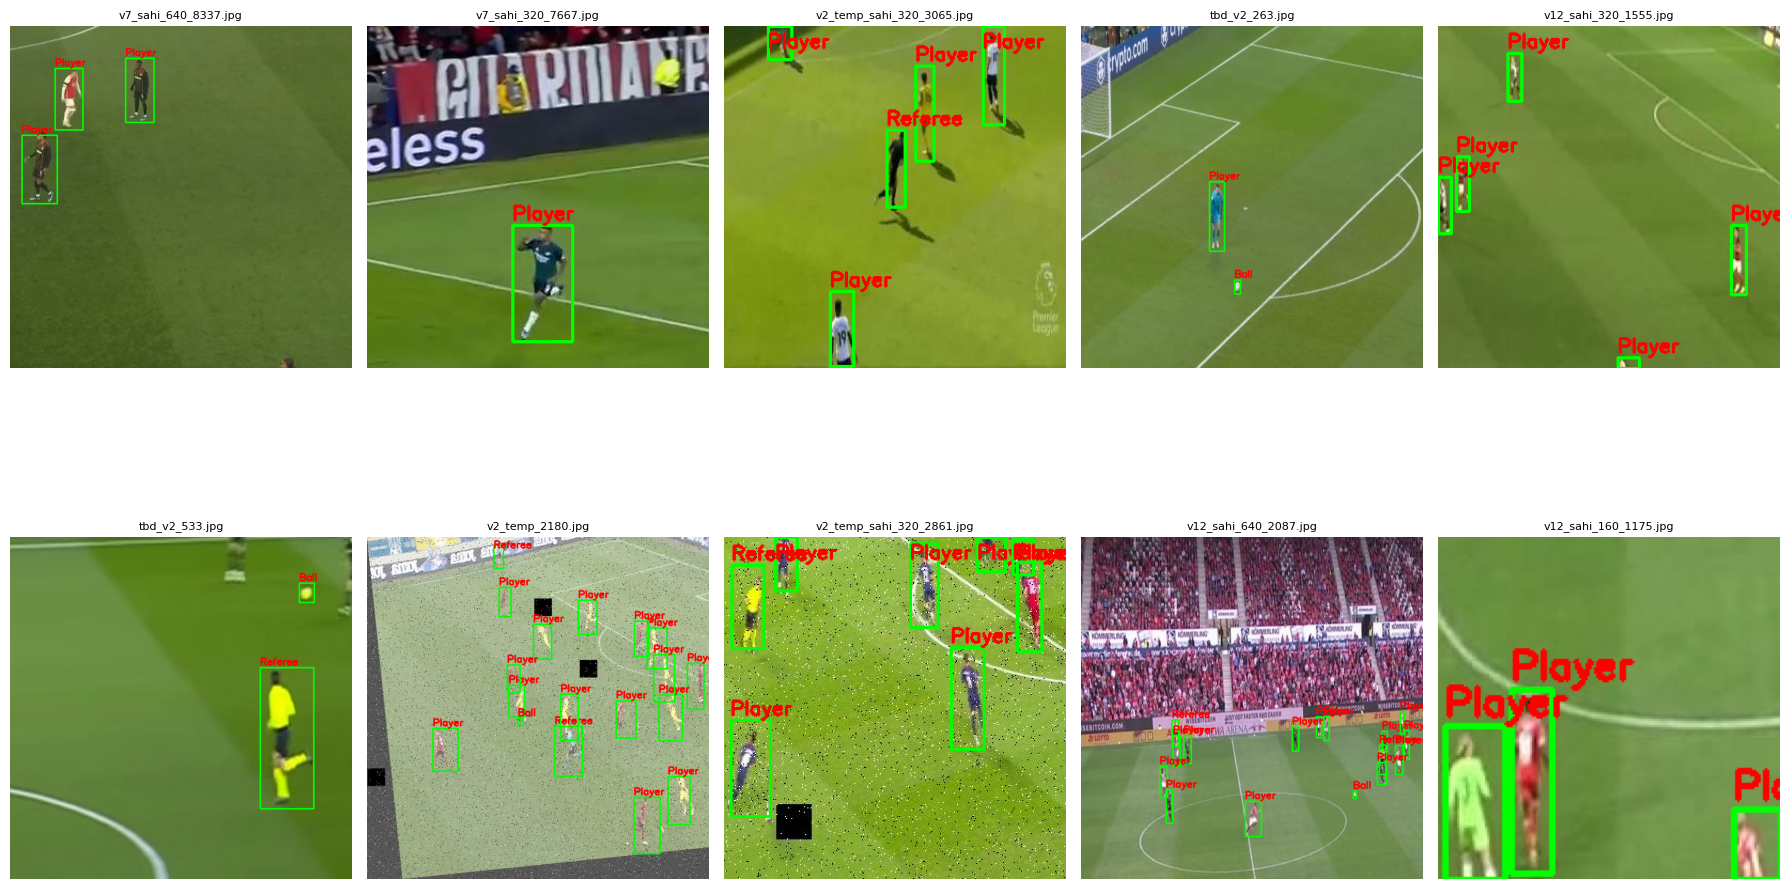

In [ ]:
import cv2
import matplotlib.pyplot as plt
import os
import random

base_path = "/content/Soccana/V1"

class_names = {
    0: "Player",
    1: "Ball",
    2: "Referee"
}

image_dir = f"{base_path}/images/train"
label_dir = f"{base_path}/labels/train"

# Non-empty labels select karo
label_files = [
    f for f in os.listdir(label_dir)
    if f.endswith(".txt") and os.path.getsize(
        os.path.join(label_dir, f)
    ) > 0
]

samples = random.sample(label_files, 10)

plt.figure(figsize=(18, 12))

for i, label_file in enumerate(samples):
    image_name = os.path.splitext(label_file)[0] + ".jpg"
    image_path = os.path.join(image_dir, image_name)
    label_path = os.path.join(label_dir, label_file)

    image = cv2.imread(image_path)

    if image is None:
        print("Image not found:", image_name)
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    h, w, _ = image.shape

    with open(label_path, "r") as f:
        for line in f:
            cls, x, y, bw, bh = map(float, line.split())

            x1 = int((x - bw / 2) * w)
            y1 = int((y - bh / 2) * h)
            x2 = int((x + bw / 2) * w)
            y2 = int((y + bh / 2) * h)

            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

            name = class_names[int(cls)]
            cv2.putText(
                image, name, (x1, max(20, y1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6,
                (255, 0, 0), 2
            )

    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title(image_name, fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
!pip install -q ultralytics

In [ ]:
import torch

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

GPU Available: True
GPU Name: Tesla T4


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

print("YOLOv8 model loaded successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLOv8 model loaded successfully!


In [ ]:
results = model.train(
    data="/content/Soccana/V1/data.yaml",
    epochs=25,
    imgsz=640,
    batch=16,
    patience=7,
    device=0,
    workers=4,
    project="/content/football_training",
    name="soccana_yolov8"
)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Soccana/V1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=soccana_yolov8, nbs=64, nms=None, opset=None, optimize=Fal

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil
import os

source = "/content/football_training/soccana_yolov8/weights/best.pt"

destination = "/content/drive/MyDrive/Football_Project/best.pt"

os.makedirs(os.path.dirname(destination), exist_ok=True)

shutil.copy2(source, destination)

print("Model successfully saved to Google Drive!")

Model successfully saved to Google Drive!


In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/football_training/soccana_yolov8/weights/best.pt"
)

print("Trained football model loaded!")

Trained football model loaded!



image 1/1 /content/Soccana/V1/images/test/v2_temp_514.jpg: 640x640 4 Players, 1 Ball, 7.7ms
Speed: 4.2ms preprocess, 7.7ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


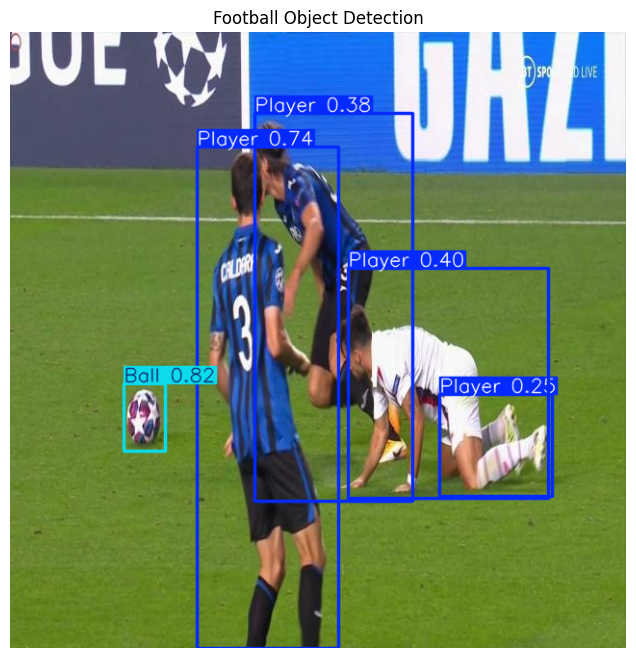

In [ ]:
import os
import random
import matplotlib.pyplot as plt

test_dir = "/content/Soccana/V1/images/test"

image_name = random.choice([
    f for f in os.listdir(test_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

image_path = os.path.join(test_dir, image_name)

results = model.predict(
    source=image_path,
    conf=0.25,
    save=True
)

annotated_image = results[0].plot()

plt.figure(figsize=(14, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.title("Football Object Detection")
plt.axis("off")
plt.show()

In [ ]:
result = results[0]

for class_id, class_name in model.names.items():
    count = sum(
        int(box.cls.item()) == class_id
        for box in result.boxes
    )

    print(f"{class_name}: {count}")

Player: 4
Ball: 1
Referee: 0


In [ ]:
import os
import random
from collections import Counter
from ultralytics import YOLO

test_dir = "/content/Soccana/V1/images/test"

image_files = [
    os.path.join(test_dir, f)
    for f in os.listdir(test_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

sample_images = random.sample(image_files, 10)

total_counts = Counter()

for image_path in sample_images:

    results = model.predict(
        source=image_path,
        conf=0.25,
        verbose=False
    )

    result = results[0]

    for box in result.boxes:
        class_id = int(box.cls.item())
        total_counts[model.names[class_id]] += 1

print("===== TOTAL DETECTIONS =====")

for name in ["Player", "Ball", "Referee"]:
    print(name, ":", total_counts[name])

===== TOTAL DETECTIONS =====
Player : 35
Ball : 2
Referee : 3


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import shutil

drive_folder = "/content/drive/MyDrive/Football_Project"

os.makedirs(drive_folder, exist_ok=True)

# Save trained model
shutil.copy2(
    "/content/football_training/soccana_yolov8/weights/best.pt",
    drive_folder + "/best.pt"
)

# Save dataset ZIP
shutil.copy2(
    "/content/Soccana/V1.zip",
    drive_folder + "/V1.zip"
)

print("Project backup completed!")

print(os.listdir(drive_folder))

Project backup completed!
['best.pt', 'V1.zip']


In [ ]:
from google.colab import files

uploaded = files.upload()

video_path = list(uploaded.keys())[0]

print("Video uploaded:", video_path)

Saving Nice move! 👏.mp4 to Nice move! 👏.mp4
Video uploaded: Nice move! 👏.mp4


In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/drive/MyDrive/Football_Project/best.pt"
)

print("Football model ready!")

Football model ready!


In [ ]:
results = model.track(
    source=video_path,
    tracker="bytetrack.yaml",
    persist=True,
    conf=0.25,
    save=True,
    project="/content/football_training",
    name="video_tracking",
    exist_ok=True,
    verbose=False
)

print("Video tracking completed!")

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 464ms
Prepared 1 package in 236ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 1.1s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to /content/football_training/video_tracking
Video tracking completed!


In [ ]:
import os

output_folder = "/content/football_training/video_tracking"

for file in os.listdir(output_folder):
    print(file)

Nice move! 👏.avi


In [ ]:
import os

output_folder = "/content/football_training/video_tracking"

for root, dirs, files in os.walk(output_folder):
    for file in files:
        print("Found:", file)

Found: Nice move! 👏.avi


In [ ]:
from google.colab import files
import os

output_folder = "/content/football_training/video_tracking"

video_files = [
    f for f in os.listdir(output_folder)
    if f.lower().endswith((".mp4", ".avi", ".mov"))
]

if video_files:
    output_path = os.path.join(output_folder, video_files[0])

    print("Downloading:", video_files[0])

    files.download(output_path)
else:
    print("No output video found!")

Downloading: Nice move! 👏.avi


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install -q opencv-python-headless scikit-learn ultralytics

In [ ]:
from ultralytics import YOLO
import cv2
import numpy as np
from sklearn.cluster import KMeans
from collections import defaultdict

model = YOLO(
    "/content/drive/MyDrive/Football_Project/best.pt"
)

video_path = "Nice move! 👏.avi"

print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
def classify_team(player_crop):

    if player_crop.size == 0:
        return "Unknown"

    hsv = cv2.cvtColor(player_crop, cv2.COLOR_BGR2HSV)

    # Blue jersey range
    blue_mask = cv2.inRange(
        hsv,
        np.array([90, 60, 40]),
        np.array([135, 255, 255])
    )

    # Red jersey range (red has two hue ranges)
    red1 = cv2.inRange(
        hsv,
        np.array([0, 60, 40]),
        np.array([12, 255, 255])
    )

    red2 = cv2.inRange(
        hsv,
        np.array([165, 60, 40]),
        np.array([180, 255, 255])
    )

    red_mask = cv2.bitwise_or(red1, red2)

    blue_pixels = cv2.countNonZero(blue_mask)
    red_pixels = cv2.countNonZero(red_mask)

    total = blue_pixels + red_pixels

    if total < 20:
        return "Unknown"

    if blue_pixels / total > 0.60:
        return "Blue Team"

    elif red_pixels / total > 0.60:
        return "Red Team"

    return "Unknown"

In [ ]:
from google.colab import files
import os

uploaded = files.upload()

video_path = list(uploaded.keys())[0]

print("Video path:", repr(video_path))
print("File exists:", os.path.exists(video_path))

Saving Nice move! 👏.mp4 to Nice move! 👏 (1).mp4
Video path: 'Nice move! 👏 (1).mp4'
File exists: True


In [ ]:
import cv2

cap = cv2.VideoCapture(video_path)

print("Video opened:", cap.isOpened())

if cap.isOpened():
    print("FPS:", cap.get(cv2.CAP_PROP_FPS))
    print("Frames:", cap.get(cv2.CAP_PROP_FRAME_COUNT))
    print("Width:", cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    print("Height:", cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()

Video opened: True
FPS: 30.0
Frames: 603.0
Width: 360.0
Height: 640.0


In [ ]:
!pip install -q scikit-learn ultralytics opencv-python-headless

import cv2
import numpy as np
import os

from ultralytics import YOLO
from sklearn.cluster import KMeans
from collections import defaultdict

model = YOLO(
    "/content/drive/MyDrive/Football_Project/best.pt"
)

print("Model loaded!")

Model loaded!


In [ ]:
def extract_jersey_color(frame, box):

    x1, y1, x2, y2 = map(int, box)

    h, w = frame.shape[:2]

    x1 = max(0, x1)
    y1 = max(0, y1)
    x2 = min(w, x2)
    y2 = min(h, y2)

    player_h = y2 - y1
    player_w = x2 - x1

    if player_h < 10 or player_w < 10:
        return None

    # Upper torso region
    torso = frame[
        y1 + int(player_h * 0.15):
        y1 + int(player_h * 0.55),
        x1 + int(player_w * 0.20):
        x1 + int(player_w * 0.80)
    ]

    if torso.size == 0:
        return None

    hsv = cv2.cvtColor(torso, cv2.COLOR_BGR2HSV)

    # Ignore low-saturation pixels such as grass,
    # white/grey clothing and background
    mask = cv2.inRange(
        hsv,
        np.array([0, 45, 40]),
        np.array([180, 255, 255])
    )

    pixels = torso[mask > 0]

    if len(pixels) < 10:
        return None

    return np.median(pixels, axis=0)

In [ ]:
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError("Video path check karo!")

track_colors = defaultdict(list)

while True:

    ret, frame = cap.read()

    if not ret:
        break

    results = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        conf=0.25,
        verbose=False
    )

    result = results[0]

    if result.boxes is None or result.boxes.id is None:
        continue

    boxes = result.boxes.xyxy.cpu().numpy()
    ids = result.boxes.id.int().cpu().tolist()
    classes = result.boxes.cls.int().cpu().tolist()

    for box, track_id, cls in zip(boxes, ids, classes):

        if cls != 0:
            continue

        color = extract_jersey_color(frame, box)

        if color is not None:
            track_colors[track_id].append(color)

cap.release()

print("Unique tracked IDs:", len(track_colors))
print("Color samples collected!")

Unique tracked IDs: 57
Color samples collected!


In [ ]:
player_features = []
player_ids = []

for track_id, colors in track_colors.items():

    if len(colors) < 2:
        continue

    average_color = np.median(colors, axis=0)

    player_features.append(average_color)
    player_ids.append(track_id)

if len(player_features) < 2:
    raise ValueError(
        "Two teams identify karne ke liye sufficient player samples nahi mile."
    )

X = np.array(player_features)

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(X)

player_teams = {
    track_id: int(label)
    for track_id, label in zip(player_ids, labels)
}

print("Automatic team classification completed!")

for team_id in range(2):

    count = sum(
        team == team_id
        for team in player_teams.values()
    )

    print(f"Team {team_id + 1}: {count} tracked players")

Automatic team classification completed!
Team 1: 27 tracked players
Team 2: 29 tracked players


In [ ]:
# Fresh model to reset tracking state
video_model = YOLO(
    "/content/drive/MyDrive/Football_Project/best.pt"
)

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

output_path = "/content/football_training/dynamic_team_analysis.mp4"

out = cv2.VideoWriter(
    output_path,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps if fps > 0 else 25,
    (width, height)
)

# Display colors are only for visualization.
# They do not determine team classification.
display_colors = {
    0: (0, 255, 0),
    1: (255, 165, 0)
}

while True:

    ret, frame = cap.read()

    if not ret:
        break

    results = video_model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        conf=0.25,
        verbose=False
    )

    result = results[0]

    if result.boxes is not None and result.boxes.id is not None:

        boxes = result.boxes.xyxy.cpu().numpy()
        ids = result.boxes.id.int().cpu().tolist()
        classes = result.boxes.cls.int().cpu().tolist()

        for box, track_id, cls in zip(boxes, ids, classes):

            x1, y1, x2, y2 = map(int, box)

            if cls == 0:

                team = player_teams.get(track_id)

                if team is None:
                    color = (180, 180, 180)
                    label = f"Unknown | ID:{track_id}"
                else:
                    color = display_colors[team]
                    label = f"Team {team + 1} | ID:{track_id}"

            elif cls == 1:
                color = (0, 255, 255)
                label = "Ball"

            elif cls == 2:
                color = (255, 255, 255)
                label = "Referee"

            else:
                continue

            cv2.rectangle(
                frame, (x1, y1), (x2, y2), color, 2
            )

            cv2.putText(
                frame,
                label,
                (x1, max(20, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                color,
                2
            )

    out.write(frame)

cap.release()
out.release()

print("Dynamic team video completed!")
print("Saved:", output_path)

Dynamic team video completed!
Saved: /content/football_training/dynamic_team_analysis.mp4


In [ ]:
from google.colab import files

files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

team1_players = [
    player_id
    for player_id, team in player_teams.items()
    if team == 0
]

team2_players = [
    player_id
    for player_id, team in player_teams.items()
    if team == 1
]

stats = {
    "Metric": [
        "Total Players",
        "Team 1 Players",
        "Team 2 Players"
    ],
    "Count": [
        len(player_teams),
        len(team1_players),
        len(team2_players)
    ]
}

df = pd.DataFrame(stats)

print(df)

           Metric  Count
0   Total Players     56
1  Team 1 Players     27
2  Team 2 Players     29


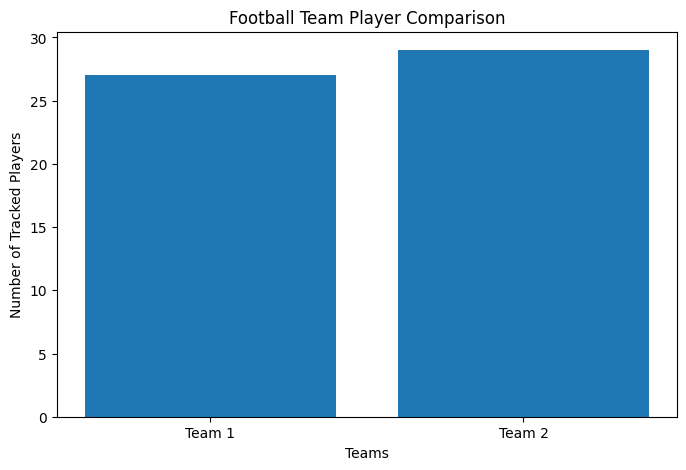

In [ ]:
import matplotlib.pyplot as plt

team_names = ["Team 1", "Team 2"]

team_counts = [
    len(team1_players),
    len(team2_players)
]

plt.figure(figsize=(8, 5))

plt.bar(team_names, team_counts)

plt.title("Football Team Player Comparison")
plt.xlabel("Teams")
plt.ylabel("Number of Tracked Players")

plt.show()

In [ ]:
df.to_csv(
    "/content/football_team_statistics.csv",
    index=False
)

print("Statistics CSV saved!")

Statistics CSV saved!


In [ ]:
from collections import defaultdict
import numpy as np
import pandas as pd

video_model = YOLO(
    "/content/drive/MyDrive/Football_Project/best.pt"
)

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)

positions = defaultdict(list)

frame_number = 0

while True:

    ret, frame = cap.read()

    if not ret:
        break

    results = video_model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        conf=0.25,
        verbose=False
    )

    result = results[0]

    if result.boxes is not None and result.boxes.id is not None:

        boxes = result.boxes.xyxy.cpu().numpy()
        ids = result.boxes.id.int().cpu().tolist()
        classes = result.boxes.cls.int().cpu().tolist()

        for box, track_id, cls in zip(boxes, ids, classes):

            if cls == 0:

                x1, y1, x2, y2 = box

                center_x = (x1 + x2) / 2
                center_y = (y1 + y2) / 2

                positions[track_id].append(
                    (frame_number, center_x, center_y)
                )

    frame_number += 1

cap.release()

print("Movement data collected!")
print("Tracked players:", len(positions))

Movement data collected!
Tracked players: 57


In [ ]:
movement_data = []

for player_id, points in positions.items():

    if len(points) < 2:
        continue

    total_distance = 0

    for i in range(1, len(points)):

        x1, y1 = points[i-1][1], points[i-1][2]
        x2, y2 = points[i][1], points[i][2]

        distance = np.sqrt(
            (x2-x1)**2 + (y2-y1)**2
        )

        total_distance += distance

    duration = (
        points[-1][0] - points[0][0]
    ) / fps if fps > 0 else 0

    avg_speed = (
        total_distance / duration
        if duration > 0 else 0
    )

    movement_data.append({
        "Player_ID": player_id,
        "Team": player_teams.get(player_id, "Unknown"),
        "Total_Movement_Pixels": round(total_distance, 2),
        "Average_Speed_Pixels_Per_Second": round(avg_speed, 2),
        "Frames_Tracked": len(points)
    })

movement_df = pd.DataFrame(movement_data)

display(movement_df.head(10))

,Player_ID,Team,Total_Movement_Pixels,Average_Speed_Pixels_Per_Second,Frames_Tracked
0,1,0,388.950012,49.029999,235
1,2,1,176.759995,76.849998,70
2,3,0,437.119995,55.099998,239
3,4,0,223.789993,54.580002,124
4,5,0,101.389999,37.099998,83
5,6,1,162.419998,46.849998,91
6,7,0,29.290001,23.120001,39
7,8,0,286.679993,44.110001,191
8,9,1,70.110001,23.370001,91
9,10,1,123.139999,42.959999,87


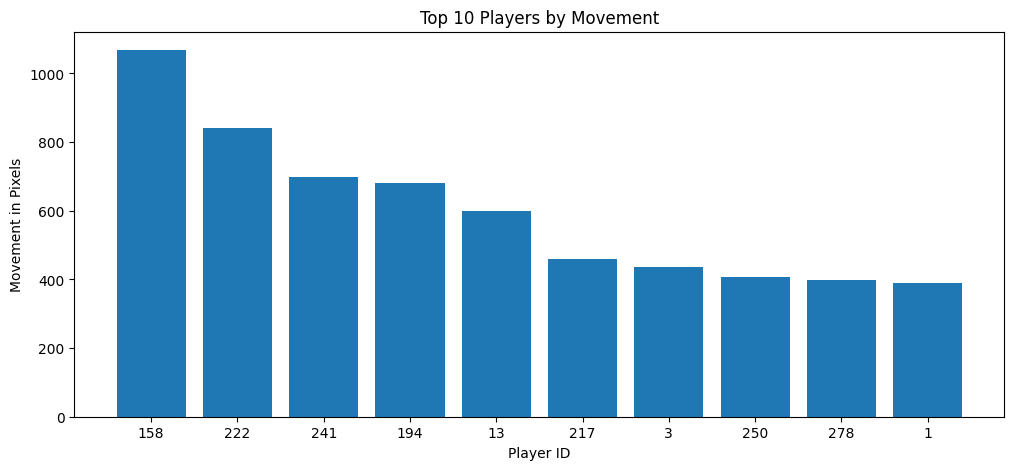

In [ ]:
if not movement_df.empty:

    top_players = movement_df.nlargest(
        10, "Total_Movement_Pixels"
    )

    plt.figure(figsize=(12, 5))

    plt.bar(
        top_players["Player_ID"].astype(str),
        top_players["Total_Movement_Pixels"]
    )

    plt.title("Top 10 Players by Movement")
    plt.xlabel("Player ID")
    plt.ylabel("Movement in Pixels")

    plt.show()

    movement_df.to_csv(
        "/content/player_movement_statistics.csv",
        index=False
    )

In [ ]:
!pip install -q streamlit

In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

os.makedirs(PROJECT_DIR, exist_ok=True)

os.chdir(PROJECT_DIR)

print("Current folder:", os.getcwd())
print("Files:", os.listdir())

Current folder: /content/drive/MyDrive/Football_Project
Files: ['best.pt', 'V1.zip']


In [ ]:
%%writefile analytics.py

import os
import cv2
import pandas as pd
from ultralytics import YOLO


def process_video(
    video_path,
    model_path,
    output_path,
    progress_callback=None,
    confidence=0.25
):

    model = YOLO(model_path)

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise ValueError("Video open nahi hui!")

    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    os.makedirs(
        os.path.dirname(output_path),
        exist_ok=True
    )

    writer = cv2.VideoWriter(
        output_path,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps if fps > 0 else 25,
        (width, height)
    )

    player_data = []
    frame_number = 0

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        results = model.track(
            frame,
            persist=True,
            tracker="bytetrack.yaml",
            conf=confidence,
            verbose=False
        )

        result = results[0]

        if result.boxes is not None:

            for box in result.boxes:

                cls = int(box.cls[0])

                if cls != 0:
                    continue

                coords = box.xyxy[0].cpu().numpy()

                x1, y1, x2, y2 = map(int, coords)

                if box.id is not None:
                    player_id = int(box.id[0])
                else:
                    player_id = -1

                cx = (x1 + x2) / 2
                cy = (y1 + y2) / 2

                player_data.append({
                    "Frame": frame_number,
                    "Player_ID": player_id,
                    "X": cx,
                    "Y": cy
                })

        annotated_frame = result.plot()

        writer.write(annotated_frame)

        frame_number += 1

        if progress_callback and total_frames > 0:
            progress_callback(
                frame_number / total_frames
            )

    cap.release()
    writer.release()

    df = pd.DataFrame(player_data)

    if not df.empty:

        df = df[df["Player_ID"] != -1]

        movement = {}

        for player_id, group in df.groupby("Player_ID"):

            group = group.sort_values("Frame")

            dx = group["X"].diff()
            dy = group["Y"].diff()

            distance = (
                (dx ** 2 + dy ** 2) ** 0.5
            ).sum()

            movement[player_id] = distance

        players_df = pd.DataFrame([
            {
                "Player_ID": pid,
                "Movement_Pixels": distance
            }
            for pid, distance in movement.items()
        ])

    else:

        players_df = pd.DataFrame(
            columns=["Player_ID", "Movement_Pixels"]
        )

    teams_df = pd.DataFrame(
        columns=["Team", "Unique_Players", "Possession_Percent"]
    )

    players_df.to_csv(
        "outputs/player_statistics.csv",
        index=False
    )

    teams_df.to_csv(
        "outputs/team_statistics.csv",
        index=False
    )

    return {
        "players": players_df,
        "teams": teams_df,
        "total_frames": frame_number,
        "output_video": output_path
    }

Writing analytics.py


In [ ]:
%%writefile app.py

import os
import uuid
import streamlit as st
import pandas as pd

from analytics import process_video

st.set_page_config(
    page_title="Football Analytics",
    page_icon="⚽",
    layout="wide"
)

st.title("⚽ Football Analytics Dashboard")

st.write(
    "YOLOv8 | ByteTrack | Player Performance Analytics"
)

model_path = st.text_input(
    "Model Path",
    value="best.pt"
)

confidence = st.slider(
    "Detection Confidence",
    0.10,
    0.90,
    0.25
)

uploaded_video = st.file_uploader(
    "Upload Football Match Video",
    type=["mp4", "avi", "mov", "mkv"]
)

if uploaded_video:

    st.video(uploaded_video)

    if st.button("Start Football Analysis"):

        os.makedirs("outputs", exist_ok=True)

        video_path = (
            "outputs/input_" +
            uuid.uuid4().hex[:8] + ".avi"
        )

        output_path = (
            "outputs/processed_" +
            uuid.uuid4().hex[:8] + ".mp4"
        )

        with open(video_path, "wb") as f:
            f.write(uploaded_video.getbuffer())

        progress = st.progress(0)

        try:

            result = process_video(
                video_path,
                model_path,
                output_path,
                progress_callback=lambda x:
                    progress.progress(min(int(x * 100), 100)),
                confidence=confidence
            )

            st.success("Analysis completed!")

            st.subheader("Match Overview")

            c1, c2, c3 = st.columns(3)

            c1.metric(
                "Unique Players",
                result["players"]["Player_ID"].nunique()
            )

            c2.metric(
                "Total Frames",
                result["total_frames"]
            )

            c3.metric(
                "Tracked Players",
                len(result["players"])
            )

            st.subheader("Processed Match Video")

            st.video(output_path)

            st.download_button(
                "Download Processed Video",
                open(output_path, "rb").read(),
                file_name="football_analysis.mp4"
            )

            st.subheader("Player Statistics")

            st.dataframe(
                result["players"],
                use_container_width=True
            )

            st.bar_chart(
                result["players"].set_index("Player_ID")[
                    "Movement_Pixels"
                ]
            )

            st.download_button(
                "Download Player CSV",
                result["players"].to_csv(index=False),
                file_name="player_statistics.csv"
            )

        except Exception as e:

            st.error(str(e))

Writing app.py


In [ ]:
import os

print(os.listdir())

assert os.path.exists("analytics.py")
assert os.path.exists("app.py")

print("Both files created successfully!")

['best.pt', 'V1.zip', 'analytics.py', 'app.py']
Both files created successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

os.chdir(PROJECT_DIR)

print(os.listdir())

['best.pt', 'V1.zip', 'analytics.py', 'app.py']


In [ ]:
%%writefile analytics.py

import os
import cv2
import numpy as np
import pandas as pd

from collections import defaultdict
from ultralytics import YOLO
from sklearn.cluster import KMeans


# ==========================================
# 1. JERSEY COLOR EXTRACTION
# ==========================================

def extract_jersey_color(frame, box):

    x1, y1, x2, y2 = map(int, box)

    h, w = frame.shape[:2]

    x1 = max(0, x1)
    y1 = max(0, y1)
    x2 = min(w, x2)
    y2 = min(h, y2)

    player_h = y2 - y1
    player_w = x2 - x1

    if player_h < 10 or player_w < 10:
        return None

    torso = frame[
        y1 + int(player_h * 0.15):
        y1 + int(player_h * 0.55),
        x1 + int(player_w * 0.20):
        x1 + int(player_w * 0.80)
    ]

    if torso.size == 0:
        return None

    hsv = cv2.cvtColor(torso, cv2.COLOR_BGR2HSV)

    mask = cv2.inRange(
        hsv,
        np.array([0, 45, 40]),
        np.array([180, 255, 255])
    )

    pixels = torso[mask > 0]

    if len(pixels) < 10:
        return None

    return np.median(pixels, axis=0)


# ==========================================
# 2. MAIN ANALYTICS FUNCTION
# ==========================================

def process_video(
    video_path,
    model_path,
    output_path,
    progress_callback=None,
    confidence=0.25
):

    os.makedirs("outputs", exist_ok=True)
    os.makedirs(os.path.dirname(output_path), exist_ok=True)

    model = YOLO(model_path)

    # ======================================
    # FIRST PASS: COLLECT PLAYER COLORS
    # ======================================

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise ValueError("Video open nahi hui!")

    track_colors = defaultdict(list)

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    frame_no = 0

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        results = model.track(
            frame,
            persist=True,
            tracker="bytetrack.yaml",
            conf=confidence,
            verbose=False
        )

        result = results[0]

        if (
            result.boxes is not None
            and result.boxes.id is not None
        ):

            boxes = result.boxes.xyxy.cpu().numpy()
            ids = result.boxes.id.int().cpu().tolist()
            classes = result.boxes.cls.int().cpu().tolist()

            for box, track_id, cls in zip(
                boxes, ids, classes
            ):

                if cls != 0:
                    continue

                color = extract_jersey_color(
                    frame, box
                )

                if color is not None:
                    track_colors[track_id].append(color)

        frame_no += 1

        if progress_callback and total_frames > 0:
            progress_callback(
                0.45 * frame_no / total_frames
            )

    cap.release()

    # ======================================
    # THIRD: AUTOMATIC TEAM CLASSIFICATION
    # ======================================

    player_features = []
    player_ids = []

    for track_id, colors in track_colors.items():

        if len(colors) < 2:
            continue

        average_color = np.median(
            colors, axis=0
        )

        player_features.append(average_color)
        player_ids.append(track_id)

    if len(player_features) < 2:

        raise ValueError(
            "Two teams identify karne ke liye "
            "sufficient player color samples nahi mile."
        )

    X = np.array(player_features)

    kmeans = KMeans(
        n_clusters=2,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X)

    player_teams = {
        track_id: int(label)
        for track_id, label in zip(player_ids, labels)
    }

    print("Automatic team classification completed!")

    for team_id in range(2):

        count = sum(
            team == team_id
            for team in player_teams.values()
        )

        print(
            f"Team {team_id + 1}: {count} tracked players"
        )

    # ======================================
    # SECOND PASS: VIDEO ANNOTATION
    # ======================================

    cap = cv2.VideoCapture(video_path)
    model = YOLO(model_path)

    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    fps = fps if fps > 0 else 25

    writer = cv2.VideoWriter(
        output_path,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (width, height)
    )

    if not writer.isOpened():
        cap.release()
        raise ValueError("Output video writer open nahi hua!")

    player_records = []
    possession_counts = defaultdict(int)

    player_positions = defaultdict(list)

    ball_count = 0
    referee_count = 0
    frame_no = 0

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        results = model.track(
            frame,
            persist=True,
            tracker="bytetrack.yaml",
            conf=confidence,
            verbose=False
        )

        result = results[0]

        players_in_frame = []
        ball_center = None

        if result.boxes is not None:

            boxes = result.boxes.xyxy.cpu().numpy()
            classes = result.boxes.cls.int().cpu().tolist()

            if result.boxes.id is not None:
                ids = result.boxes.id.int().cpu().tolist()
            else:
                ids = [-1] * len(boxes)

            for box, track_id, cls in zip(
                boxes, ids, classes
            ):

                x1, y1, x2, y2 = map(int, box)

                cx = (x1 + x2) / 2
                cy = (y1 + y2) / 2

                # PLAYER
                if cls == 0:

                    team_id = player_teams.get(
                        track_id, -1
                    )

                    if team_id == 0:
                        color = (255, 100, 0)
                        team_name = "Team 1"

                    elif team_id == 1:
                        color = (0, 0, 255)
                        team_name = "Team 2"

                    else:
                        color = (200, 200, 200)
                        team_name = "Unknown"

                    cv2.rectangle(
                        frame,
                        (x1, y1),
                        (x2, y2),
                        color,
                        2
                    )

                    cv2.putText(
                        frame,
                        f"ID {track_id} | {team_name}",
                        (x1, max(y1 - 8, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.5,
                        color,
                        2
                    )

                    if track_id >= 0:

                        players_in_frame.append(
                            (track_id, team_id, cx, cy)
                        )

                        player_positions[track_id].append(
                            (frame_no, cx, cy)
                        )

                        player_records.append({
                            "Frame": frame_no,
                            "Player_ID": track_id,
                            "Team": team_name,
                            "X": cx,
                            "Y": cy
                        })

                # BALL
                elif cls == 1:

                    ball_count += 1
                    ball_center = (cx, cy)

                    cv2.rectangle(
                        frame,
                        (x1, y1),
                        (x2, y2),
                        (0, 255, 255),
                        2
                    )

                    cv2.putText(
                        frame,
                        "BALL",
                        (x1, max(y1 - 8, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.5,
                        (0, 255, 255),
                        2
                    )

                # REFEREE
                elif cls == 2:

                    referee_count += 1

                    cv2.rectangle(
                        frame,
                        (x1, y1),
                        (x2, y2),
                        (255, 255, 255),
                        2
                    )

                    cv2.putText(
                        frame,
                        "REFEREE",
                        (x1, max(y1 - 8, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.5,
                        (255, 255, 255),
                        2
                    )

        # APPROXIMATE BALL POSSESSION

        if ball_center is not None and players_in_frame:

            distances = []

            for pid, team_id, px, py in players_in_frame:

                distance = np.sqrt(
                    (px - ball_center[0]) ** 2
                    + (py - ball_center[1]) ** 2
                )

                distances.append(
                    (distance, team_id)
                )

            nearest_distance, nearest_team = min(
                distances, key=lambda x: x[0]
            )

            if nearest_distance < 120 and nearest_team in [0, 1]:

                possession_counts[nearest_team] += 1

        writer.write(frame)

        frame_no += 1

        if progress_callback and total_frames > 0:

            progress_callback(
                0.45 + 0.55 * frame_no / total_frames
            )

    cap.release()
    writer.release()

    # ======================================
    # PLAYER MOVEMENT STATISTICS
    # ======================================

    movement_records = []

    for pid, positions in player_positions.items():

        positions.sort(key=lambda x: x[0])

        distance = 0

        for i in range(1, len(positions)):

            previous = positions[i - 1]
            current = positions[i]

            # Ignore gaps between tracking observations
            if current[0] - previous[0] > 2:
                continue

            dx = current[1] - previous[1]
            dy = current[2] - previous[2]

            distance += np.sqrt(dx ** 2 + dy ** 2)

        movement_records.append({
            "Player_ID": pid,
            "Team": (
                f"Team {player_teams[pid] + 1}"
                if pid in player_teams else "Unknown"
            ),
            "Movement_Pixels": round(distance, 2),
            "Frames_Tracked": len(positions)
        })

    players_df = pd.DataFrame(movement_records)

    tracking_df = pd.DataFrame(player_records)

    # ======================================
    # TEAM STATISTICS
    # ======================================

    total_possession = sum(possession_counts.values())

    team_records = []

    for team_id in range(2):

        team_players = sum(
            1 for team in player_teams.values()
            if team == team_id
        )

        possession = (
            possession_counts[team_id]
            / total_possession * 100
            if total_possession > 0 else 0
        )

        team_records.append({
            "Team": f"Team {team_id + 1}",
            "Unique_Players": team_players,
            "Possession_Percent": round(possession, 2)
        })

    teams_df = pd.DataFrame(team_records)

    # ======================================
    # SAVE CSV REPORTS
    # ======================================

    players_df.to_csv(
        "outputs/player_statistics.csv",
        index=False
    )

    teams_df.to_csv(
        "outputs/team_statistics.csv",
        index=False
    )

    tracking_df.to_csv(
        "outputs/player_tracking.csv",
        index=False
    )

    return {
        "players": players_df,
        "teams": teams_df,
        "tracking": tracking_df,
        "total_frames": frame_no,
        "ball_detections": ball_count,
        "referee_detections": referee_count,
        "output_video": output_path
    }

Overwriting analytics.py


In [ ]:
!pip install -q ultralytics scikit-learn streamlit opencv-python-headless pandas

In [ ]:
import cv2
import numpy as np
import pandas as pd
import streamlit as st

from sklearn.cluster import KMeans
from ultralytics import YOLO

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import py_compile

py_compile.compile(
    "analytics.py",
    doraise=True
)

print("Analytics engine compiled successfully!")

Analytics engine compiled successfully!


In [ ]:
%%writefile app.py

import os
import uuid
import streamlit as st
import pandas as pd

from analytics import process_video


st.set_page_config(
    page_title="Football Analytics Dashboard",
    page_icon="⚽",
    layout="wide"
)


# ==========================================
# HEADER
# ==========================================

st.title("⚽ Football Analytics Dashboard")

st.markdown(
    "### AI-Powered Football Match Analysis"
)

st.caption(
    "YOLOv8 | ByteTrack | K-Means | Player Performance"
)

st.divider()


# ==========================================
# SIDEBAR
# ==========================================

st.sidebar.title("Match Settings")

model_path = st.sidebar.text_input(
    "YOLO Model Path",
    value="best.pt"
)

confidence = st.sidebar.slider(
    "Detection Confidence",
    min_value=0.10,
    max_value=0.90,
    value=0.25,
    step=0.05
)


# ==========================================
# VIDEO UPLOAD
# ==========================================

st.subheader("Upload Football Match")

uploaded_video = st.file_uploader(
    "Choose your football video",
    type=["mp4", "avi", "mov", "mkv"]
)


if uploaded_video:

    st.video(uploaded_video)

    st.info("Video uploaded successfully!")

    if st.button(
        "Start Match Analysis",
        type="primary",
        use_container_width=True
    ):

        if not os.path.exists(model_path):

            st.error("YOLO model file not found!")

        else:

            os.makedirs("outputs", exist_ok=True)

            video_name = (
                "input_" + uuid.uuid4().hex[:8] + ".avi"
            )

            output_name = (
                "processed_" + uuid.uuid4().hex[:8] + ".mp4"
            )

            video_path = os.path.join(
                "outputs", video_name
            )

            output_path = os.path.join(
                "outputs", output_name
            )

            with open(video_path, "wb") as f:
                f.write(uploaded_video.getbuffer())

            progress = st.progress(0)

            status = st.empty()

            try:

                status.info(
                    "Analyzing video and collecting jersey colors..."
                )

                result = process_video(
                    video_path=video_path,
                    model_path=model_path,
                    output_path=output_path,
                    confidence=confidence,
                    progress_callback=lambda x: (
                        progress.progress(
                            min(int(x * 100), 100)
                        )
                    )
                )

                progress.progress(100)

                status.success(
                    "Football analysis completed!"
                )

                st.session_state["football_result"] = result

                st.session_state["output_path"] = output_path

            except Exception as e:

                status.error("Analysis failed!")

                st.exception(e)


# ==========================================
# DISPLAY ANALYTICS
# ==========================================

if "football_result" in st.session_state:

    result = st.session_state["football_result"]

    players = result["players"]
    teams = result["teams"]

    st.divider()

    st.header("📊 Match Overview")

    c1, c2, c3, c4 = st.columns(4)

    c1.metric(
        "Unique Players",
        players["Player_ID"].nunique()
    )

    c2.metric(
        "Total Frames",
        result["total_frames"]
    )

    c3.metric(
        "Ball Detections",
        result["ball_detections"]
    )

    c4.metric(
        "Referee Detections",
        result["referee_detections"]
    )

    # ======================================
    # TEAM STATISTICS
    # ======================================

    st.divider()

    st.header("🏆 Team Statistics")

    st.dataframe(
        teams,
        use_container_width=True,
        hide_index=True
    )

    st.subheader("Estimated Team Possession")

    st.bar_chart(
        teams.set_index("Team")["Possession_Percent"]
    )

    # ======================================
    # PLAYER PERFORMANCE
    # ======================================

    st.divider()

    st.header("👤 Player Performance")

    if not players.empty:

        st.dataframe(
            players,
            use_container_width=True,
            hide_index=True
        )

        st.subheader("Player Movement Comparison")

        st.bar_chart(
            players.set_index("Player_ID")[
                "Movement_Pixels"
            ]
        )

    else:

        st.warning("No tracked players found.")

    # ======================================
    # PROCESSED VIDEO
    # ======================================

    st.divider()

    st.header("🎥 Processed Match Video")

    output_path = st.session_state["output_path"]

    if os.path.exists(output_path):

        st.video(output_path)

        with open(output_path, "rb") as video_file:

            st.download_button(
                "Download Processed Video",
                data=video_file.read(),
                file_name="football_analysis.mp4",
                mime="video/mp4"
            )

    # ======================================
    # CSV DOWNLOADS
    # ======================================

    st.divider()

    st.header("📥 Download Match Reports")

    col1, col2, col3 = st.columns(3)

    with col1:

        st.download_button(
            "Player Statistics CSV",
            players.to_csv(index=False),
            file_name="player_statistics.csv",
            mime="text/csv"
        )

    with col2:

        st.download_button(
            "Team Statistics CSV",
            teams.to_csv(index=False),
            file_name="team_statistics.csv",
            mime="text/csv"
        )

    with col3:

        tracking = result["tracking"]

        st.download_button(
            "Player Tracking CSV",
            tracking.to_csv(index=False),
            file_name="player_tracking.csv",
            mime="text/csv"
        )

Overwriting app.py


In [ ]:
import py_compile

py_compile.compile("analytics.py", doraise=True)
py_compile.compile("app.py", doraise=True)

print("All files compiled successfully!")

All files compiled successfully!


In [ ]:
import os

print(os.listdir(PROJECT_DIR))

['best.pt', 'V1.zip', 'analytics.py', 'app.py', '__pycache__']


In [ ]:
%cd /content/drive/MyDrive/Football_Project

/content


In [ ]:
!pip install -q streamlit ultralytics scikit-learn pandas

In [ ]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > streamlit.log 2>&1 &

In [ ]:
import time
time.sleep(5)

print(open("streamlit.log").read()[-2000:])



2026-11-12 21:13:10.544 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.185.40.225:8501




In [ ]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼
added 22 packages in 5s
⠼
⠼3 packages are looking for funding
⠼  run `npm fund` for details
⠼npm notice
npm notice New major version of npm available! 10.8.2 -> 12.2.2
npm notice Changelog: https://github.com/npm/cli/releases/tag/v12.2.2
npm notice To update run: npm install -g npm@12.2.2
npm notice
⠼

In [ ]:
!lt --port 8501

your url is: https://yummy-ghosts-write.loca.lt
!curl -s https://loca.lt/mytunnelpassword
^C


In [ ]:
!pkill -f "streamlit run app.py" || true

^C


In [ ]:
import os
import subprocess
import time

os.chdir("/content/drive/MyDrive/Football_Project")

log_file = open("streamlit.log", "w")

streamlit_process = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(8)

print("Streamlit running:", streamlit_process.poll() is None)
print(open("streamlit.log").read()[-2000:])

Streamlit running: True


2026-11-12 21:23:28.529 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.185.40.225:8501




In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb -O cloudflared.deb

!dpkg -i cloudflared.deb

Selecting previously unselected package cloudflared.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack cloudflared.deb ...
Unpacking cloudflared (2026.11.0) ...
Setting up cloudflared (2026.11.0) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [ ]:
!cloudflared --version

cloudflared version 2026.11.0 (built 2026-11-12-12:17 UTC)


In [ ]:
!cloudflared tunnel --url http://127.0.0.1:8501 --no-autoupdate

2026-11-12T21:24:03Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-12T21:24:03Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-12T21:24:06Z INF +--------------------------------------------------------------------------------------------+
2026-11-12T21:24:06Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-12T21:24:06Z INF |  https://audience-becoming-nancy-updated.trycloudflare

In [ ]:
import requests

try:
    response = requests.get(
        "http://127.0.0.1:8501",
        timeout=15
    )

    print("Status Code:", response.status_code)
    print("Server Response:", response.text[:500])

except Exception as e:
    print("Server Error:", e)

Status Code: 200
Server Response: <!--
 Copyright (c) Streamlit Inc. (2018-2022) Snowflake Inc. (2022-2026)

 Licensed under the Apache License, Version 2.0 (the "License");
 you may not use this file except in compliance with the License.
 You may obtain a copy of the License at

     http://www.apache.org/licenses/LICENSE-2.0

 Unless required by applicable law or agreed to in writing, software
 distributed under the License is distributed on an "AS IS" BASIS,
 WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or im


In [ ]:
import os

log_path = "/content/drive/MyDrive/Football_Project/streamlit.log"

if os.path.exists(log_path):

    with open(log_path, "r") as f:
        logs = f.read()

    print(logs[-6000:])

else:
    print("streamlit.log file nahi mili!")



2026-11-12 21:23:28.529 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.185.40.225:8501

2026-11-12 21:26:21.024 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-12 21:26:23.789 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-12 21:27:41.328 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-12 21:27:41.349 Pleas

In [ ]:
#st.video(uploaded_video)

In [ ]:
#st.video(output_path)

In [ ]:
import subprocess
import time

subprocess.run(
    ["pkill", "-f", "streamlit run app.py"],
    capture_output=True
)

time.sleep(3)

In [ ]:
import subprocess

with open("streamlit.log", "w") as log:

    process = subprocess.Popen(
        [
            "streamlit", "run", "app.py",
            "--server.port", "8501",
            "--server.address", "0.0.0.0"
        ],
        stdout=log,
        stderr=subprocess.STDOUT,
        start_new_session=True
    )

print("New Streamlit process started:", process.pid)

New Streamlit process started: 52334


In [ ]:
import requests

url = "http://127.0.0.1:8501"

r = requests.get(url)

print("Status:", r.status_code)
print("Streamlit HTML loaded:", "streamlit" in r.text.lower())
print("Response length:", len(r.text))

Status: 200
Streamlit HTML loaded: True
Response length: 7863


In [ ]:
print(open("streamlit.log").read()[-5000:])



2026-11-12 21:39:33.332 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.185.40.225:8501




In [ ]:
!cloudflared tunnel --url http://127.0.0.1:8501 --no-autoupdate

2026-11-12T21:47:03Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-12T21:47:03Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-12T21:47:08Z INF +--------------------------------------------------------------------------------------------+
2026-11-12T21:47:08Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-12T21:47:08Z INF |  https://tri-jonathan-perspectives-lender.trycloudflar

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

project_path = "/content/drive/MyDrive/Football_Project"

print("Project files:")

for root, dirs, files in os.walk(project_path):
    for file in files:
        print(os.path.relpath(
            os.path.join(root, file),
            project_path
        ))

Project files:
best.pt
V1.zip
analytics.py
app.py
streamlit.log
cloudflared.deb
__pycache__/analytics.cpython-313.pyc
__pycache__/app.cpython-313.pyc
outputs/input_0c97850c.avi
outputs/processed_e6cdc1db.mp4
outputs/player_statistics.csv
outputs/team_statistics.csv
outputs/player_tracking.csv
outputs/input_5fd0166a.avi
outputs/processed_d4069aa6.mp4
outputs/input_c32d8f15.avi
outputs/processed_fa8a950a.mp4


In [ ]:
import os

folder = "/content/drive/MyDrive/Football_Project/backups"

print(os.listdir(folder) if os.path.exists(folder) else "Backup folder not created")

['Football_Project_Backup.zip']


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

os.chdir(
    "/content/drive/MyDrive/Football_Project"
)

print(os.listdir())

['cloudflared.deb', 'V1.zip', 'best.pt', 'analytics.py', '__pycache__', 'app.py', 'outputs', 'backups', 'streamlit.log']


In [ ]:
!pip install ultralytics streamlit \
    opencv-python-headless \
    scikit-learn pandas plotly

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 14.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 51.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 108.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [ultralytics]


In [ ]:
import os

print(os.path.exists("best.pt"))
print(os.path.exists("app.py"))
print(os.path.exists("analytics.py"))

True
True
True


In [ ]:
import subprocess

log = open("streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0"
    ],
    stdout=log,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

print("Streamlit started:", process.pid)

Streamlit started: 1112


In [ ]:
!cloudflared tunnel --url http://127.0.0.1:8501 --no-autoupdate

/bin/bash: line 1: cloudflared: command not found


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 \
-O /usr/local/bin/cloudflared

!chmod +x /usr/local/bin/cloudflared

!cloudflared --version

cloudflared version 2026.11.0 (built 2026-11-12-12:17 UTC)


In [ ]:
!curl -I http://127.0.0.1:8501

HTTP/1.1 200 OK
date: Fri, 13 Nov 2026 15:18:08 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 7863
last-modified: Fri, 13 Nov 2026 15:11:04 GMT
etag: "11b1d5fe818aec0dc37a1ae3f253a958"
cache-control: no-cache



In [ ]:
!cloudflared tunnel --url http://127.0.0.1:8501 --no-autoupdate

2026-11-13T15:18:18Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-13T15:18:18Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-13T15:18:23Z INF +--------------------------------------------------------------------------------------------+
2026-11-13T15:18:23Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-13T15:18:23Z INF |  https://colleges-carnival-venue-carrying.trycloudflar

In [ ]:
import requests

try:
    response = requests.get(
        "http://127.0.0.1:8501",
        timeout=15
    )

    print("Status:", response.status_code)
    print("Streamlit server is responding!")

except Exception as e:
    print("Streamlit server problem:", e)

Status: 200
Streamlit server is responding!


In [ ]:
!tail -n 100 /content/drive/MyDrive/Football_Project/streamlit.log



2026-11-13 15:11:34.411 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.7.158.158:8501

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 197ms
Prepared 1 package in 43ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

2026-11-13 15:20:13.981 Please replace `use_container_width` with `width`.

`use_container_width` will be removed

In [ ]:
!apt-get -qq install ffmpeg

In [ ]:
import os

video_input = "/content/drive/MyDrive/Football_Project/outputs/processed_video.mp4"

print("Video exists:", os.path.exists(video_input))

if os.path.exists(video_input):
    print("Video size:", round(os.path.getsize(video_input)/1024/1024, 2), "MB")

Video exists: False


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

os.chdir(PROJECT_DIR)

print(os.listdir(PROJECT_DIR))

['cloudflared.deb', 'V1.zip', 'best.pt', 'analytics.py', '__pycache__', 'app.py', 'outputs', 'backups', 'streamlit.log']


In [ ]:
!pip install -q streamlit ultralytics lap scikit-learn opencv-python-headless plotly pandas

In [ ]:
!pkill -f "streamlit run" || true

^C


In [ ]:
!streamlit run app.py \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    > /content/streamlit.log 2>&1 &

In [ ]:
import time
import requests

time.sleep(5)

response = requests.get("http://127.0.0.1:8501")

print("Status:", response.status_code)

Status: 200


In [ ]:
!ffmpeg -i output.mp4 \
-vcodec libx264 \
-crf 28 \
-preset fast \
-acodec aac \
output_compressed.mp4

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [ ]:
!pip install -q gradio ultralytics lap scikit-learn plotly

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

os.chdir(PROJECT_DIR)

print(os.listdir())

['cloudflared.deb', 'V1.zip', 'best.pt', 'analytics.py', '__pycache__', 'app.py', 'outputs', 'backups', 'streamlit.log']


In [ ]:

import gradio as gr
import os
import cv2
import pandas as pd

from ultralytics import YOLO

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

MODEL_PATH = os.path.join(PROJECT_DIR, "best.pt")

model = YOLO(MODEL_PATH)


def process_video(video_path):

    if video_path is None:
        raise gr.Error("Please upload a football video.")

    output_dir = os.path.join(PROJECT_DIR, "output")
    os.makedirs(output_dir, exist_ok=True)

    results = model.track(
        source=video_path,
        persist=True,
        tracker="bytetrack.yaml",
        conf=0.25,
        save=True,
        project=output_dir,
        name="tracking",
        exist_ok=True,
        verbose=False
    )

    # Locate processed video
    result_dir = os.path.join(output_dir, "tracking")

    videos = [
        os.path.join(result_dir, f)
        for f in os.listdir(result_dir)
        if f.lower().endswith((".mp4", ".avi", ".mov"))
    ]

    if not videos:
        raise gr.Error("Processed video was not generated.")

    processed_video = videos[-1]

    # Detection counts
    counts = {"Player": 0, "Ball": 0, "Referee": 0}

    for result in results:
        if result.boxes is not None:
            for cls in result.boxes.cls.int().tolist():
                class_name = model.names[cls]
                if class_name in counts:
                    counts[class_name] += 1

    stats = pd.DataFrame(
        list(counts.items()),
        columns=["Object", "Detections"]
    )

    return processed_video, stats


with gr.Blocks(title="Football Analytics") as demo:

    gr.Markdown(
        "# ⚽ FOOTBALL ANALYTICS SYSTEM"
    )

    gr.Markdown(
        "AI-powered Football Player, Ball and Referee Detection"
    )

    with gr.Row():

        video_input = gr.Video(
            label="Upload Football Match Video",
            sources=["upload"],
            format="mp4"
        )

        video_output = gr.Video(
            label="Processed Video",
            format="mp4"
        )

    process_btn = gr.Button(
        "Analyze Match",
        variant="primary"
    )

    statistics = gr.Dataframe(
        label="Detection Statistics"
    )

    process_btn.click(
        fn=process_video,
        inputs=video_input,
        outputs=[video_output, statistics]
    )


demo.launch(
    share=True,
    debug=True
)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://8876ca3af7c60f130c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to /content/drive/MyDrive/Football_Project/output/tracking


/usr/local/lib/python3.13/dist-packages/gradio/components/video.py:469: UserWarning: Video does not have browser-compatible container or codec. Converting to mp4.
  warnings.warn(


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to /content/drive/MyDrive/Football_Project/output/tracking


/usr/local/lib/python3.13/dist-packages/gradio/components/video.py:469: UserWarning: Video does not have browser-compatible container or codec. Converting to mp4.
  warnings.warn(


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://8876ca3af7c60f130c.gradio.live


In [ ]:
%cd /content/drive/MyDrive/Football_Project

!python gradio_app.py

/content
python3: can't open file '/content/drive/MyDrive/Football_Project/gradio_app.py': [Errno 2] No such file or directory


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

print(os.listdir(PROJECT_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['cloudflared.deb', 'V1.zip', 'best.pt', 'analytics.py', '__pycache__', 'app.py', 'outputs', 'backups', 'streamlit.log', '.gradio', 'output']


In [ ]:
!pip install -q gradio ultralytics opencv-python-headless

In [ ]:
%%writefile /content/drive/MyDrive/Football_Project/gradio_app.py

import gradio as gr
import os

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

def football_dashboard(video):

    if video is None:
        return "Please upload a football video.", None

    video_path = video

    return (
        "Video uploaded successfully! "
        "Football analytics integration is ready.",
        video_path
    )


with gr.Blocks(title="Football Analytics Dashboard") as demo:

    gr.Markdown("# ⚽ Football Analytics Dashboard")
    gr.Markdown("AI Powered Football Match Analysis")

    with gr.Row():

        with gr.Column():

            video_input = gr.Video(
                label="Upload Football Match Video"
            )

            analyze_btn = gr.Button(
                "Analyze Match",
                variant="primary"
            )

        with gr.Column():

            status = gr.Textbox(
                label="Analysis Status"
            )

            output_video = gr.Video(
                label="Processed Football Video"
            )

    analyze_btn.click(
        fn=football_dashboard,
        inputs=video_input,
        outputs=[status, output_video]
    )


demo.launch(
    share=True,
    debug=True
)

Writing /content/drive/MyDrive/Football_Project/gradio_app.py


In [ ]:
import os

print(os.listdir(PROJECT_DIR))

print(
    "File exists:",
    os.path.exists(PROJECT_DIR + "/gradio_app.py")
)

['cloudflared.deb', 'V1.zip', 'best.pt', 'analytics.py', '__pycache__', 'app.py', 'outputs', 'backups', 'streamlit.log', '.gradio', 'output', 'gradio_app.py']
File exists: True


In [ ]:
%cd /content/drive/MyDrive/Football_Project

!python gradio_app.py

/content
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://1e2c6a4bdaec914200.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
Keyboard interruption in main thread... closing server.
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 3957, in block_thread
    time.sleep(0.1)
    ~~~~~~~~~~^^^^^
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/content/drive/MyDrive/Football_Project/gradio_app.py", line 56, in <module>
    demo.launch(
    ~~~~~~~~~~~^
        share=True,
        ^^^^^^^^^^^
        debug=True
        ^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 37

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

os.chdir(PROJECT_DIR)

print("Project files:")
print(os.listdir(PROJECT_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project files:
['cloudflared.deb', 'V1.zip', 'best.pt', 'analytics.py', '__pycache__', 'app.py', 'outputs', 'backups', 'streamlit.log', '.gradio', 'output', 'gradio_app.py']


In [ ]:
!pip install -q gradio ultralytics opencv-python-headless pandas

In [ ]:

%%writefile /content/drive/MyDrive/Football_Project/gradio_app.py

import os
import uuid
import gradio as gr
import pandas as pd

from analytics import process_video

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")
MODEL_PATH = os.path.join(PROJECT_DIR, "best.pt")

os.makedirs(OUTPUT_DIR, exist_ok=True)


def football_analysis(video, confidence, progress=gr.Progress()):

    if video is None:
        raise gr.Error("Please upload a football video.")

    if not os.path.exists(MODEL_PATH):
        raise gr.Error("best.pt model file not found!")

    video_path = video

    if not os.path.exists(video_path):
        raise gr.Error("Uploaded video file not found!")

    output_path = os.path.join(
        OUTPUT_DIR,
        "processed_" + uuid.uuid4().hex[:8] + ".mp4"
    )

    try:

        result = process_video(
            video_path=video_path,
            model_path=MODEL_PATH,
            output_path=output_path,
            progress_callback=lambda x: progress(
                x,
                desc="Analyzing football match..."
            ),
            confidence=confidence
        )

        players_df = result["players"]

        csv_path = os.path.join(
            OUTPUT_DIR,
            "player_statistics.csv"
        )

        players_df.to_csv(csv_path, index=False)

        unique_players = players_df["Player_ID"].nunique()

        summary = f"""
FOOTBALL MATCH ANALYSIS COMPLETED

Total Frames: {result['total_frames']}

Unique Players: {unique_players}

Tracked Player Records: {len(players_df)}

Processed Video: Ready
"""

        return (
            output_path,
            summary,
            players_df,
            csv_path
        )

    except Exception as e:
        raise gr.Error(f"Analysis failed: {str(e)}")


with gr.Blocks(
    theme=gr.themes.Soft(),
    title="Football Analytics Dashboard"
) as demo:

    gr.Markdown(
        """
        # ⚽ Football Analytics Dashboard

        ### AI Powered Football Match Analysis

        Upload your football match video and analyze player performance.
        """
    )

    with gr.Row():

        with gr.Column():

            video_input = gr.Video(
                label="Upload Football Match Video"
            )

            confidence = gr.Slider(
                minimum=0.10,
                maximum=0.90,
                value=0.25,
                step=0.05,
                label="Detection Confidence"
            )

            analyze_btn = gr.Button(
                "Start Football Analysis",
                variant="primary"
            )

        with gr.Column():

            output_video = gr.Video(
                label="Processed Match Video"
            )

            summary = gr.Textbox(
                label="Match Overview",
                lines=8
            )

    gr.Markdown("## 📊 Player Performance Statistics")

    player_table = gr.Dataframe(
        label="Player Statistics",
        interactive=False
    )

    csv_download = gr.File(
        label="Download Player Statistics CSV"
    )

    analyze_btn.click(
        fn=football_analysis,
        inputs=[
            video_input,
            confidence
        ],
        outputs=[
            output_video,
            summary,
            player_table,
            csv_download
        ]
    )


demo.launch(
    share=True,
    debug=False
)


Overwriting /content/drive/MyDrive/Football_Project/gradio_app.py


In [ ]:
import os

file_path = os.path.join(
    PROJECT_DIR,
    "gradio_app.py"
)

print("Gradio file exists:", os.path.exists(file_path))
print("Project files:", os.listdir(PROJECT_DIR))

Gradio file exists: True
Project files: ['cloudflared.deb', 'V1.zip', 'best.pt', 'analytics.py', '__pycache__', 'app.py', 'outputs', 'backups', 'streamlit.log', '.gradio', 'output', 'gradio_app.py']


In [ ]:
%cd /content/drive/MyDrive/Football_Project

!python gradio_app.py

/content
/content/drive/MyDrive/Football_Project/gradio_app.py:81: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://a05ebb94cbc198cdd8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
Automatic team classification completed!
Team 1: 27 tracked players
Team 2: 29 tracked players
/usr/local/lib/python3.13/dist-packages/gradio/components/video.py:469: UserWarning: Video does not have browser-compatible container or codec. Converting to mp4.
  warnings.warn(
Keyboard interruption in main thread... closing server.
Traceback (most recent call last):
  File "/usr/local/lib

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

print(os.listdir(PROJECT_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['cloudflared.deb', 'V1.zip', 'best.pt', 'analytics.py', '__pycache__', 'app.py', 'outputs', 'backups', 'streamlit.log', '.gradio', 'output', 'gradio_app.py']


In [ ]:
import os
import shutil
from datetime import datetime

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

BACKUP_DIR = os.path.join(
    PROJECT_DIR, "backups",
    "final_backup_" + datetime.now().strftime("%Y%m%d_%H%M%S")
)

os.makedirs(BACKUP_DIR, exist_ok=True)

for filename in [
    "analytics.py",
    "gradio_app.py",
    "app.py",
    "best.pt"
]:
    source = os.path.join(PROJECT_DIR, filename)

    if os.path.exists(source):
        shutil.copy2(
            source,
            os.path.join(BACKUP_DIR, filename)
        )

print("Backup completed!")
print("Backup location:", BACKUP_DIR)

Backup completed!
Backup location: /content/drive/MyDrive/Football_Project/backups/final_backup_20261113_162219


In [ ]:
%cd /content/drive/MyDrive/Football_Project

!pip install -q gradio ultralytics opencv-python-headless pandas numpy scikit-learn matplotlib

/content


In [ ]:

%%writefile /content/drive/MyDrive/Football_Project/gradio_app.py

import os
import uuid
import subprocess
import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt

from analytics import process_video

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")
MODEL_PATH = os.path.join(PROJECT_DIR, "best.pt")

os.makedirs(OUTPUT_DIR, exist_ok=True)


def football_analysis(video, confidence, progress=gr.Progress()):

    if video is None:
        raise gr.Error("Please upload a football video.")

    if not os.path.exists(MODEL_PATH):
        raise gr.Error("best.pt model file not found!")

    video_path = video

    if not os.path.exists(video_path):
        raise gr.Error("Uploaded video not found!")

    unique_id = uuid.uuid4().hex[:8]

    output_path = os.path.join(
        OUTPUT_DIR,
        f"processed_{unique_id}.mp4"
    )

    try:
        result = process_video(
            video_path=video_path,
            model_path=MODEL_PATH,
            output_path=output_path,
            progress_callback=lambda x: progress(
                x, desc="Analyzing football match..."
            ),
            confidence=confidence
        )

        players_df = result["players"]
        teams_df = result["teams"]
        tracking_df = result["tracking"]

        # Save CSV reports
        player_csv = os.path.join(
            OUTPUT_DIR, f"player_statistics_{unique_id}.csv"
        )
        team_csv = os.path.join(
            OUTPUT_DIR, f"team_statistics_{unique_id}.csv"
        )
        tracking_csv = os.path.join(
            OUTPUT_DIR, f"player_tracking_{unique_id}.csv"
        )

        players_df.to_csv(player_csv, index=False)
        teams_df.to_csv(team_csv, index=False)
        tracking_df.to_csv(tracking_csv, index=False)

        # Convert processed video for browser compatibility
        browser_video = os.path.join(
            OUTPUT_DIR, f"browser_{unique_id}.mp4"
        )

        try:
            subprocess.run(
                [
                    "ffmpeg", "-y",
                    "-i", output_path,
                    "-c:v", "libx264",
                    "-pix_fmt", "yuv420p",
                    "-movflags", "+faststart",
                    "-an",
                    browser_video
                ],
                check=True,
                stdout=subprocess.DEVNULL,
                stderr=subprocess.DEVNULL
            )

            if os.path.exists(browser_video):
                output_video = browser_video
            else:
                output_video = output_path

        except Exception:
            output_video = output_path

        # Match overview
        unique_players = (
            players_df["Player_ID"].nunique()
            if not players_df.empty else 0
        )

        summary = f"""
FOOTBALL MATCH ANALYSIS COMPLETED

Total Frames: {result['total_frames']}

Unique Players: {unique_players}

Ball Detections: {result['ball_detections']}

Referee Detections: {result['referee_detections']}

Team Classification: Completed

Processed Video: Ready
"""

        # Player movement chart
        if not players_df.empty:

            chart_df = players_df.nlargest(
                15, "Movement_Pixels"
            ).sort_values("Movement_Pixels")

            fig1, ax1 = plt.subplots(figsize=(9, 5))

            ax1.barh(
                chart_df["Player_ID"].astype(str),
                chart_df["Movement_Pixels"]
            )

            ax1.set_title("Top 15 Players - Movement")
            ax1.set_xlabel("Movement (Pixels)")
            ax1.set_ylabel("Player ID")

            fig1.tight_layout()

        else:
            fig1 = None

        # Team possession chart
        if not teams_df.empty:

            fig2, ax2 = plt.subplots(figsize=(7, 4))

            ax2.bar(
                teams_df["Team"],
                teams_df["Possession_Percent"]
            )

            ax2.set_title("Team Possession Analysis")
            ax2.set_ylabel("Possession (%)")
            ax2.set_ylim(0, 100)

            fig2.tight_layout()

        else:
            fig2 = None

        return (
            output_video,
            summary,
            players_df,
            teams_df,
            fig1,
            fig2,
            player_csv,
            team_csv,
            tracking_csv
        )

    except Exception as e:
        raise gr.Error(f"Analysis failed: {str(e)}")


with gr.Blocks(
    theme=gr.themes.Soft(),
    title="Football Analytics Dashboard"
) as demo:

    gr.Markdown(
        """
        # ⚽ Football Analytics Dashboard

        ### AI-Powered Football Match Analysis

        Player Detection | Team Classification |
        Ball Detection | Performance Analytics
        """
    )

    with gr.Row():

        with gr.Column():

            video_input = gr.Video(
                label="Upload Football Match Video"
            )

            confidence = gr.Slider(
                minimum=0.10,
                maximum=0.90,
                value=0.25,
                step=0.05,
                label="Detection Confidence"
            )

            analyze_btn = gr.Button(
                "Start Football Analysis",
                variant="primary"
            )

        with gr.Column():

            output_video = gr.Video(
                label="Processed Match Video"
            )

            summary = gr.Textbox(
                label="Match Overview",
                lines=9,
                interactive=False
            )

    gr.Markdown("## 📊 Player Performance Statistics")

    player_table = gr.Dataframe(
        label="Player Statistics",
        interactive=False
    )

    with gr.Row():

        player_chart = gr.Plot(
            label="Player Movement Analysis"
        )

        team_chart = gr.Plot(
            label="Team Possession Analysis"
        )

    gr.Markdown("## 🏆 Team Statistics")

    team_table = gr.Dataframe(
        label="Team Classification and Possession",
        interactive=False
    )

    gr.Markdown("## 📥 Download Match Reports")

    with gr.Row():

        player_download = gr.File(
            label="Player Statistics CSV"
        )

        team_download = gr.File(
            label="Team Statistics CSV"
        )

        tracking_download = gr.File(
            label="Player Tracking CSV"
        )

    analyze_btn.click(
        fn=football_analysis,
        inputs=[
            video_input,
            confidence
        ],
        outputs=[
            output_video,
            summary,
            player_table,
            team_table,
            player_chart,
            team_chart,
            player_download,
            team_download,
            tracking_download
        ]
    )


demo.launch(
    share=True,
    debug=False,
    server_name="0.0.0.0"
)


Overwriting /content/drive/MyDrive/Football_Project/gradio_app.py


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

for filename in [
    "best.pt",
    "analytics.py",
    "gradio_app.py"
]:
    path = os.path.join(PROJECT_DIR, filename)

    print(
        filename,
        "FOUND" if os.path.exists(path) else "MISSING"
    )

best.pt FOUND
analytics.py FOUND
gradio_app.py FOUND


In [ ]:
%cd /content/drive/MyDrive/Football_Project

!python gradio_app.py

[Errno 2] No such file or directory: '/content/drive/MyDrive/Football_Project'
/content
python3: can't open file '/content/gradio_app.py': [Errno 2] No such file or directory


In [ ]:

import os

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

required_files = [
    "best.pt",
    "analytics.py",
    "app.py",
    "gradio_app.py"
]

print("FOOTBALL PROJECT FILE CHECK")
print("-" * 40)

for file in required_files:
    path = os.path.join(PROJECT_DIR, file)

    if os.path.exists(path):
        print("OK:", file, "-",
              round(os.path.getsize(path) / (1024*1024), 2), "MB")
    else:
        print("MISSING:", file)

print("\nOUTPUTS FOLDER:")

output_dir = os.path.join(PROJECT_DIR, "outputs")

if os.path.exists(output_dir):
    print(os.listdir(output_dir))
else:
    print("Outputs folder missing!")


FOOTBALL PROJECT FILE CHECK
----------------------------------------
MISSING: best.pt
MISSING: analytics.py
MISSING: app.py
MISSING: gradio_app.py

OUTPUTS FOLDER:
Outputs folder missing!


In [ ]:

import os

print("SEARCHING FOR FOOTBALL PROJECT FILES")
print("=" * 50)

search_locations = [
    "/content/drive/MyDrive",
    "/content"
]

target_files = [
    "best.pt",
    "analytics.py",
    "app.py",
    "gradio_app.py"
]

for location in search_locations:
    print(f"\nSearching in: {location}")

    if not os.path.exists(location):
        print("Location not found!")
        continue

    for root, dirs, files in os.walk(location):
        dirs[:] = [
            d for d in dirs
            if d not in ["__pycache__", ".cache"]
        ]

        for filename in target_files:
            if filename in files:
                print("FOUND:", os.path.join(root, filename))


SEARCHING FOR FOOTBALL PROJECT FILES

Searching in: /content/drive/MyDrive
Location not found!

Searching in: /content


In [ ]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

print("PROJECT FOLDER EXISTS:", os.path.exists(PROJECT_DIR))

if os.path.exists(PROJECT_DIR):
    print("\nPROJECT FILES:")
    for item in os.listdir(PROJECT_DIR):
        print(item)
else:
    print("Folder path check karna hoga.")


PROJECT FOLDER EXISTS: True

PROJECT FILES:
cloudflared.deb
V1.zip
best.pt
__pycache__
app.py
outputs
backups
streamlit.log
.gradio
output
analytics.py
gradio_app.py


In [ ]:

import os

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

required_files = [
    "best.pt",
    "analytics.py",
    "app.py",
    "gradio_app.py"
]

print("FINAL FILE VERIFICATION")
print("-" * 40)

for file in required_files:
    path = os.path.join(PROJECT_DIR, file)
    print(
        file,
        "SAVED ✅" if os.path.isfile(path) else "MISSING ❌"
    )


FINAL FILE VERIFICATION
----------------------------------------
best.pt SAVED ✅
analytics.py SAVED ✅
app.py SAVED ✅
gradio_app.py SAVED ✅


In [ ]:

import os

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

for folder in ["outputs", "backups"]:
    path = os.path.join(PROJECT_DIR, folder)

    print(f"\n{folder.upper()}:")

    if os.path.exists(path):
        print("Folder exists ✅")
        for item in os.listdir(path):
            print(" -", item)
    else:
        print("Folder not found")



OUTPUTS:
Folder exists ✅
 - input_0c97850c.avi
 - processed_e6cdc1db.mp4
 - input_5fd0166a.avi
 - processed_d4069aa6.mp4
 - input_c32d8f15.avi
 - processed_fa8a950a.mp4
 - input_19f793b2.avi
 - processed_b9c72308.mp4
 - processed_eafd2680.mp4
 - processed_e1a7d957.mp4
 - player_statistics_e1a7d957.csv
 - team_statistics_e1a7d957.csv
 - player_tracking_e1a7d957.csv
 - browser_e1a7d957.mp4
 - team_statistics.csv
 - player_tracking.csv
 - player_statistics.csv

BACKUPS:
Folder exists ✅
 - final_backup_20261113_162219


In [ ]:

!pip install -q ultralytics lap gradio opencv-python-headless


In [ ]:

import torch
import cv2
import pandas
import gradio
import ultralytics

print("GPU:", torch.cuda.is_available())
print("OpenCV:", cv2.__version__)
print("Gradio:", gradio.__version__)
print("Ultralytics:", ultralytics.__version__)

print("\nALL PACKAGES INSTALLED SUCCESSFULLY!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU: False
OpenCV: 5.0.0
Gradio: 6.31.0
Ultralytics: 8.4.212

ALL PACKAGES INSTALLED SUCCESSFULLY!


In [ ]:

from ultralytics import YOLO
import os

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

model_path = os.path.join(PROJECT_DIR, "best.pt")

model = YOLO(model_path)

print("YOLO MODEL LOADED SUCCESSFULLY!")


YOLO MODEL LOADED SUCCESSFULLY!


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

print("PROJECT FILE VERIFICATION")
print("-" * 40)

required_files = [
    "best.pt",
    "analytics.py",
    "app.py",
    "gradio_app.py"
]

for file in required_files:
    path = os.path.join(PROJECT_DIR, file)

    if os.path.exists(path):
        print(file, "SAVED ✅")
    else:
        print(file, "MISSING ❌")

print("\nOutputs folder:")
print(os.path.exists(os.path.join(PROJECT_DIR, "outputs")))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT FILE VERIFICATION
----------------------------------------
best.pt SAVED ✅
analytics.py SAVED ✅
app.py SAVED ✅
gradio_app.py SAVED ✅

Outputs folder:
True


In [ ]:

import sys

sys.path.insert(0, PROJECT_DIR)

from analytics import process_video

print("Analytics module imported successfully!")


Analytics module imported successfully!


In [ ]:

%cd /content/drive/MyDrive/Football_Project

!python gradio_app.py


/content/drive/MyDrive/Football_Project
/content/drive/MyDrive/Football_Project/gradio_app.py:177: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(
* Running on local URL:  http://0.0.0.0:7860
* Running on public URL: https://0e0a312aa6baaf9ee7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
Automatic team classification completed!
Team 1: 27 tracked players
Team 2: 29 tracked players
ERROR:    Exception in ASGI application
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/uvicorn/protocols/http/httptools_impl.py", line 422, in run_asgi
    result = await app(  # type: ignore[func-returns-value]
             ^^

In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

print("FINAL PROJECT BACKUP")
print("----------------------------")

files = [
    "best.pt",
    "analytics.py",
    "app.py",
    "gradio_app.py"
]

for file in files:
    path = os.path.join(PROJECT_DIR, file)
    print(file, "SAVED ✅" if os.path.exists(path) else "MISSING ❌")

print("\nOUTPUT FILES:")

output_dir = os.path.join(PROJECT_DIR, "outputs")

if os.path.exists(output_dir):
    for file in os.listdir(output_dir):
        print(file)
else:
    print("Outputs folder empty or missing")

FINAL PROJECT BACKUP
----------------------------
best.pt SAVED ✅
analytics.py SAVED ✅
app.py SAVED ✅
gradio_app.py SAVED ✅

OUTPUT FILES:
input_0c97850c.avi
processed_e6cdc1db.mp4
input_5fd0166a.avi
processed_d4069aa6.mp4
input_c32d8f15.avi
processed_fa8a950a.mp4
input_19f793b2.avi
processed_b9c72308.mp4
processed_eafd2680.mp4
processed_e1a7d957.mp4
player_statistics_e1a7d957.csv
team_statistics_e1a7d957.csv
player_tracking_e1a7d957.csv
browser_e1a7d957.mp4
team_statistics.csv
player_tracking.csv
player_statistics.csv
processed_4bae06b7.mp4
player_statistics_4bae06b7.csv
team_statistics_4bae06b7.csv
player_tracking_4bae06b7.csv
browser_4bae06b7.mp4


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

print("FINAL PROJECT FILES")
print("-" * 40)

for item in os.listdir(PROJECT_DIR):
    path = os.path.join(PROJECT_DIR, item)

    if os.path.isfile(path):
        print("FILE:", item)
    else:
        print("FOLDER:", item)

print("\nOUTPUT FILES:")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")

if os.path.exists(OUTPUT_DIR):
    for file in os.listdir(OUTPUT_DIR):
        print(file)
else:
    print("Outputs folder missing!")

FINAL PROJECT FILES
----------------------------------------
FILE: cloudflared.deb
FILE: V1.zip
FILE: best.pt
FOLDER: __pycache__
FILE: app.py
FOLDER: outputs
FOLDER: backups
FILE: streamlit.log
FOLDER: .gradio
FOLDER: output
FILE: analytics.py
FILE: gradio_app.py

OUTPUT FILES:
input_0c97850c.avi
processed_e6cdc1db.mp4
input_5fd0166a.avi
processed_d4069aa6.mp4
input_c32d8f15.avi
processed_fa8a950a.mp4
input_19f793b2.avi
processed_b9c72308.mp4
processed_eafd2680.mp4
processed_e1a7d957.mp4
player_statistics_e1a7d957.csv
team_statistics_e1a7d957.csv
player_tracking_e1a7d957.csv
browser_e1a7d957.mp4
team_statistics.csv
player_tracking.csv
player_statistics.csv
processed_4bae06b7.mp4
player_statistics_4bae06b7.csv
team_statistics_4bae06b7.csv
player_tracking_4bae06b7.csv
browser_4bae06b7.mp4


In [ ]:
import os
import shutil
from datetime import datetime

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"
BACKUP_DIR = os.path.join(PROJECT_DIR, "backups")

os.makedirs(BACKUP_DIR, exist_ok=True)

backup_name = "Football_Project_Backup_" + datetime.now().strftime("%Y%m%d_%H%M%S")
backup_path = os.path.join(BACKUP_DIR, backup_name)

shutil.copytree(
    PROJECT_DIR,
    backup_path,
    ignore=shutil.ignore_patterns("backups")
)

print("Backup created successfully!")
print(backup_path)

Backup created successfully!
/content/drive/MyDrive/Football_Project/backups/Football_Project_Backup_20261113_170914


In [ ]:
!pip install ultralytics scikit-learn opencv-python pandas numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 65.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
from ultralytics import YOLO
import cv2
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans

print("All imports successful!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
All imports successful!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

model = YOLO(PROJECT_DIR + "/best.pt")

print("Model loaded successfully!")
print("Model classes:", model.names)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model loaded successfully!
Model classes: {0: 'Player', 1: 'Ball', 2: 'Referee'}


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Football_Project/V1.zip"

with zipfile.ZipFile(zip_path, 'r') as z:

    files = z.namelist()

    print("TOTAL DATASET FILES:", len(files))

    print("\nDATASET FOLDER STRUCTURE:")

    for f in files[:50]:
        print(f)

TOTAL DATASET FILES: 23372

DATASET FOLDER STRUCTURE:
V1/
V1/coco_test_annotations/
V1/coco_test_annotations/_annotations.coco.json
V1/coco_train_annotations/
V1/coco_train_annotations/_annotations.coco.json
V1/data.yaml
V1/images/
V1/images/test/
V1/images/test/spt_v2_0.jpg
V1/images/test/spt_v2_1.jpg
V1/images/test/spt_v2_2.jpg
V1/images/test/spt_v2_3.jpg
V1/images/test/spt_v2_4.jpg
V1/images/test/spt_v2_5.jpg
V1/images/test/spt_v2_6.jpg
V1/images/test/spt_v2_7.jpg
V1/images/test/spt_v2_8.jpg
V1/images/test/spt_v2_9.jpg
V1/images/test/spt_v2_sahi_160_10.jpg
V1/images/test/spt_v2_sahi_160_11.jpg
V1/images/test/spt_v2_sahi_160_12.jpg
V1/images/test/spt_v2_sahi_160_13.jpg
V1/images/test/spt_v2_sahi_160_14.jpg
V1/images/test/spt_v2_sahi_160_15.jpg
V1/images/test/spt_v2_sahi_160_16.jpg
V1/images/test/spt_v2_sahi_160_17.jpg
V1/images/test/spt_v2_sahi_160_18.jpg
V1/images/test/spt_v2_sahi_160_19.jpg
V1/images/test/spt_v2_sahi_320_20.jpg
V1/images/test/spt_v2_sahi_320_21.jpg
V1/images/test/s

In [ ]:
yaml_files = [
    f for f in files
    if f.endswith('.yaml') or f.endswith('.yml')
]

print("Dataset YAML files:", yaml_files)

Dataset YAML files: ['V1/data.yaml']


In [ ]:
import os

project = "/content/drive/MyDrive/Football_Project"

for root, dirs, files in os.walk(project):

    for file in files:

        if file in [
            "results.csv",
            "args.yaml",
            "data.yaml",
            "confusion_matrix.png"
        ]:
            print(os.path.join(root, file))

In [ ]:

import os

search_root = "/content/drive/MyDrive"

target_files = [
    "results.csv",
    "args.yaml",
    "data.yaml",
    "confusion_matrix.png",
    "best.pt",
    "last.pt"
]

print("SEARCHING TRAINING FILES...")
print("-" * 50)

for root, dirs, files in os.walk(search_root):

    # Unnecessary folders skip karo
    dirs[:] = [
        d for d in dirs
        if d not in [".cache", "__pycache__", ".gradio"]
    ]

    for file in files:
        if file in target_files:
            print(os.path.join(root, file))


SEARCHING TRAINING FILES...
--------------------------------------------------
/content/drive/MyDrive/Football_Project/best.pt
/content/drive/MyDrive/Football_Project/backups/final_backup_20261113_162219/best.pt
/content/drive/MyDrive/Football_Project/backups/Football_Project_Backup_20261113_170914/best.pt


In [ ]:

import zipfile
import os

zip_path = "/content/drive/MyDrive/Football_Project/V1.zip"

if os.path.exists(zip_path):

    with zipfile.ZipFile(zip_path, "r") as z:

        print("DATASET ZIP FOUND!")
        print("Total files:", len(z.namelist()))

        for item in z.namelist()[:40]:
            print(item)

else:
    print("V1.zip not found at this location")


DATASET ZIP FOUND!
Total files: 23372
V1/
V1/coco_test_annotations/
V1/coco_test_annotations/_annotations.coco.json
V1/coco_train_annotations/
V1/coco_train_annotations/_annotations.coco.json
V1/data.yaml
V1/images/
V1/images/test/
V1/images/test/spt_v2_0.jpg
V1/images/test/spt_v2_1.jpg
V1/images/test/spt_v2_2.jpg
V1/images/test/spt_v2_3.jpg
V1/images/test/spt_v2_4.jpg
V1/images/test/spt_v2_5.jpg
V1/images/test/spt_v2_6.jpg
V1/images/test/spt_v2_7.jpg
V1/images/test/spt_v2_8.jpg
V1/images/test/spt_v2_9.jpg
V1/images/test/spt_v2_sahi_160_10.jpg
V1/images/test/spt_v2_sahi_160_11.jpg
V1/images/test/spt_v2_sahi_160_12.jpg
V1/images/test/spt_v2_sahi_160_13.jpg
V1/images/test/spt_v2_sahi_160_14.jpg
V1/images/test/spt_v2_sahi_160_15.jpg
V1/images/test/spt_v2_sahi_160_16.jpg
V1/images/test/spt_v2_sahi_160_17.jpg
V1/images/test/spt_v2_sahi_160_18.jpg
V1/images/test/spt_v2_sahi_160_19.jpg
V1/images/test/spt_v2_sahi_320_20.jpg
V1/images/test/spt_v2_sahi_320_21.jpg
V1/images/test/spt_v2_sahi_320_2

In [ ]:

from ultralytics import YOLO
import os

model_path = "/content/drive/MyDrive/Football_Project/best.pt"

model = YOLO(model_path)

print("MODEL INFORMATION")
print("-" * 40)

print("Model type:", model.task)
print("Model architecture:", model.model.__class__.__name__)
print("Classes:", model.names)
print("Number of classes:", len(model.names))


MODEL INFORMATION
----------------------------------------
Model type: detect
Model architecture: DetectionModel
Classes: {0: 'Player', 1: 'Ball', 2: 'Referee'}
Number of classes: 3


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import torch
from ultralytics import YOLO
import os

project = "/content/drive/MyDrive/Football_Project"

model_path = os.path.join(project, "best.pt")

model = YOLO(model_path)

print("MODEL DETAILS")
print("-----------------------")

print("Model task:", model.task)
print("Model architecture:", type(model.model).__name__)
print("Class names:", model.names)

print("\nCHECKING TRAINING METADATA")

ckpt = torch.load(
    model_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint keys:", ckpt.keys())

print("Training arguments:")
print(ckpt.get("train_args", "Not available"))

print("\nOriginal model YAML:")
print(ckpt.get("yaml", "Not available"))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MODEL DETAILS
-----------------------
Model task: detect
Model architecture: DetectionModel
Class names: {0: 'Player', 1: 'Ball', 2: 'Referee'}

CHECKING TRAINING METADATA
Checkpoint keys: dict_keys(['date', 'version', 'license', 'docs', 'epoch', 'best_fitness', 'stopper', 'model', 'ema', 'updates', 'modelopt', 'optimizer', 'scaler', 'train_args', 'train_metrics', 'train_results', 'git'])
Training arguments:
{'task': 'detect', 'mode': 'train', 'model': 'yolov8n.pt', 'data': '/content/Soccana/V1/data.yaml', 'epochs': 25, 'time': None, 'patience': 7, 'batch': 16, 'imgsz': 640, 'save': True, 'save_period': -1, 'cache': False, 'device': '0', 'workers': 4, 'project': '/content/football_training', 'name': 'soccana_yolov8', 'exist_ok': False, 'pretrained': True, 'cls_remap': True, 'optimizer': 'AdamW', 'verbose': True, 'seed': 0, 'deterministic': True, 'single_cls':

In [ ]:

import zipfile
import os
from collections import Counter

zip_path = "/content/drive/MyDrive/Football_Project/V1.zip"

with zipfile.ZipFile(zip_path, 'r') as z:

    files = z.namelist()

    print("DATASET ANALYSIS")
    print("-----------------------")

    images = [
        f for f in files
        if f.lower().endswith(
            ('.jpg', '.jpeg', '.png')
        )
    ]

    print("Total images:", len(images))

    for split in ["train", "valid", "test"]:

        split_images = [
            f for f in images
            if f"images/{split}/" in f
        ]

        print(
            f"{split.upper()} images:",
            len(split_images)
        )

    print("\nDATA.YAML CONTENT")

    yaml_file = [
        f for f in files
        if f.endswith("data.yaml")
    ]

    if yaml_file:
        print(z.read(yaml_file[0]).decode())


DATASET ANALYSIS
-----------------------
Total images: 11683
TRAIN images: 8677
VALID images: 0
TEST images: 2996

DATA.YAML CONTENT
names:
  0: Player
  1: Ball
  2: Referee
path: F:\Datasets\SoccerAnalysis_Final\V1
train: images/train
val: images/test



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

import os

print(os.listdir(PROJECT_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['cloudflared.deb', 'V1.zip', 'best.pt', '__pycache__', 'app.py', 'outputs', 'backups', 'streamlit.log', '.gradio', 'output', 'analytics.py', 'gradio_app.py']


In [ ]:
import os
import zipfile

ZIP_PATH = os.path.join(PROJECT_DIR, "V1.zip")
DATASET_DIR = "/content/Football_Project_Dataset"

if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError("V1.zip Google Drive mein nahi mili!")

os.makedirs(DATASET_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATASET_DIR)

print("Dataset extracted successfully!")

for root, dirs, files in os.walk(DATASET_DIR):
    if "data.yaml" in files:
        print("DATA YAML FOUND:", os.path.join(root, "data.yaml"))

Dataset extracted successfully!
DATA YAML FOUND: /content/Football_Project_Dataset/V1/data.yaml


In [ ]:
import glob

yaml_files = glob.glob(
    DATASET_DIR + "/**/data.yaml",
    recursive=True
)

if not yaml_files:
    raise FileNotFoundError("data.yaml dataset mein nahi mili!")

DATA_YAML = yaml_files[0]
DATA_ROOT = os.path.dirname(DATA_YAML)

print("Dataset YAML:", DATA_YAML)
print("Dataset Root:", DATA_ROOT)

print("\nChecking folders:")

for folder in [
    "images/train",
    "images/test",
    "labels/train",
    "labels/test"
]:
    path = os.path.join(DATA_ROOT, folder)
    print(folder, ":", os.path.exists(path))

Dataset YAML: /content/Football_Project_Dataset/V1/data.yaml
Dataset Root: /content/Football_Project_Dataset/V1

Checking folders:
images/train : True
images/test : True
labels/train : True
labels/test : True


In [ ]:
import yaml

with open(DATA_YAML, "r") as f:
    data = yaml.safe_load(f)

data["path"] = DATA_ROOT

# Dataset mein separate validation folder nahi hai.
# Existing test images ko test evaluation ke liye use karenge.
data["train"] = "images/train"
data["val"] = "images/test"
data["test"] = "images/test"

FIXED_YAML = os.path.join(
    PROJECT_DIR,
    "data_fixed.yaml"
)

with open(FIXED_YAML, "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print("Corrected YAML created!")
print("\n", open(FIXED_YAML).read())

Corrected YAML created!

 names:
  0: Player
  1: Ball
  2: Referee
path: /content/Football_Project_Dataset/V1
train: images/train
val: images/test
test: images/test



In [ ]:
from ultralytics import YOLO
import torch

MODEL_PATH = os.path.join(PROJECT_DIR, "best.pt")

model = YOLO(MODEL_PATH)

print("MODEL LOADED SUCCESSFULLY!")
print("GPU Available:", torch.cuda.is_available())
print("Classes:", model.names)

MODEL LOADED SUCCESSFULLY!
GPU Available: True
Classes: {0: 'Player', 1: 'Ball', 2: 'Referee'}


In [ ]:
print("MODEL TEST EVALUATION STARTED")

metrics = model.val(
    data=FIXED_YAML,
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    project=os.path.join(PROJECT_DIR, "evaluation"),
    name="final_test",
    exist_ok=True
)

print("\n===== FINAL MODEL RESULTS =====")

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

print("\nEVALUATION COMPLETED!")

MODEL TEST EVALUATION STARTED
Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 802.5±505.3 MB/s, size: 70.9 KB)
val: Scanning /content/Football_Project_Dataset/V1/labels/test... 2996 images, 1041 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2996/2996 682.3it/s 4.4s
val: /content/Football_Project_Dataset/V1/images/test/v2_temp_510.jpg: 3 duplicate labels removed
val: /content/Football_Project_Dataset/V1/images/test/v2_temp_sahi_160_528.jpg: 1 duplicate labels removed
val: /content/Football_Project_Dataset/V1/images/test/v2_temp_sahi_160_531.jpg: 1 duplicate labels removed
val: /content/Football_Project_Dataset/V1/images/test/v2_temp_sahi_320_772.jpg: 1 duplicate labels removed
val: New cache created: /content/Football_Project_Dataset/V1/labels/test.cache
                 Class     Images  Instances      Box(P          R      mA

In [ ]:
import pandas as pd

results = pd.DataFrame([{
    "Precision": metrics.box.mp,
    "Recall": metrics.box.mr,
    "mAP50": metrics.box.map50,
    "mAP50-95": metrics.box.map
}])

save_path = os.path.join(
    PROJECT_DIR,
    "evaluation_results.csv"
)

results.to_csv(save_path, index=False)

print(results)
print("\nResults saved at:", save_path)

   Precision    Recall    mAP50  mAP50-95
0   0.849744  0.700655  0.76198  0.434653

Results saved at: /content/drive/MyDrive/Football_Project/evaluation_results.csv


In [ ]:
evaluation_folder = os.path.join(
    PROJECT_DIR,
    "evaluation",
    "final_test"
)

print("EVALUATION FILES:")

for root, dirs, files in os.walk(evaluation_folder):
    for file in files:
        print(file)

EVALUATION FILES:
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_pred.jpg
val_batch1_labels.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg
BoxPR_curve.png
BoxF1_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix_normalized.png
confusion_matrix.png


In [ ]:
import os
import shutil

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

backup_dir = os.path.join(PROJECT_DIR, "Final_Evaluation_Backup")
os.makedirs(backup_dir, exist_ok=True)

# Evaluation CSV copy
csv_file = os.path.join(PROJECT_DIR, "evaluation_results.csv")

if os.path.exists(csv_file):
    shutil.copy2(csv_file, backup_dir)

# Evaluation graphs and images copy
evaluation_folder = os.path.join(
    PROJECT_DIR, "evaluation", "final_test"
)

if os.path.exists(evaluation_folder):
    shutil.copytree(
        evaluation_folder,
        os.path.join(backup_dir, "final_test"),
        dirs_exist_ok=True
    )

print("Evaluation backup successfully saved!")
print("Location:", backup_dir)

Evaluation backup successfully saved!
Location: /content/drive/MyDrive/Football_Project/Final_Evaluation_Backup


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

files = [
    "best.pt",
    "analytics.py",
    "app.py",
    "gradio_app.py"
]

print("FINAL PROJECT VERIFICATION")
print("---------------------------")

for file in files:
    path = os.path.join(PROJECT_DIR, file)

    if os.path.exists(path):
        print(file, "SAVED ✅")
    else:
        print(file, "MISSING ❌")

print("Outputs folder:",
      os.path.exists(os.path.join(PROJECT_DIR, "outputs")))

print("Backups folder:",
      os.path.exists(os.path.join(PROJECT_DIR, "backups")))


FINAL PROJECT VERIFICATION
---------------------------
best.pt SAVED ✅
analytics.py SAVED ✅
app.py SAVED ✅
gradio_app.py SAVED ✅
Outputs folder: True
Backups folder: True


In [ ]:
!pip install -q ultralytics gradio scikit-learn pandas

In [ ]:
import os
import sys

PROJECT_DIR = "/content/drive/MyDrive/Football_Project"

os.chdir(PROJECT_DIR)

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

print("Working Directory:", os.getcwd())
print("Project Files:", os.listdir(PROJECT_DIR))


Working Directory: /content/drive/MyDrive/Football_Project
Project Files: ['cloudflared.deb', 'V1.zip', 'best.pt', '__pycache__', 'app.py', 'outputs', 'backups', 'streamlit.log', '.gradio', 'output', 'analytics.py', 'gradio_app.py', 'data_fixed.yaml', 'evaluation', 'evaluation_results.csv', 'Final_Evaluation_Backup']


In [ ]:
import torch
import cv2
import gradio as gr
import ultralytics

from ultralytics import YOLO

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("CPU Mode: Analysis will be slower")

model = YOLO("best.pt")

print("YOLO Model Loaded Successfully!")
print("Ultralytics:", ultralytics.__version__)
print("Gradio:", gr.__version__)
print("OpenCV:", cv2.__version__)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU Available: False
CPU Mode: Analysis will be slower
YOLO Model Loaded Successfully!
Ultralytics: 8.4.212
Gradio: 6.31.0
OpenCV: 5.0.0


In [ ]:
from analytics import process_video

print("Analytics module imported successfully!")
print("Football Analytics Ready!")


Analytics module imported successfully!
Football Analytics Ready!


In [ ]:
%cd /content/drive/MyDrive/Football_Project

!python gradio_app.py


/content
/content/drive/MyDrive/Football_Project/gradio_app.py:177: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(
* Running on local URL:  http://0.0.0.0:7860
* Running on public URL: https://fb8040a02b80053d5a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.18 environment at: /usr
Resolved 2 packages in 467ms
Prepared 1 package in 221ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 1.0s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Automatic team classification c